# CS781 – Merged Phase 1–4 (4 Phase-1 backbones)

| Backbone | Typical `.pt` | Arch |
|----------|---------------|------|
| `custom_mha` | `legal_lm_custom_mha.pt` | RoPE + MHA + SwiGLU |
| `mla_moe` | `legal_lm_mla_moe.pt` | MLA + MoE |
| `gqa_conv` | `legal_lm_gqa_conv.pt` | RoPE + GQA + Dual-path FFN |
| `gqa_alibi` | `legal_lm_alibi_gqa.pt` | **ALiBi + GQA** |

**Phase 1 = load only.** Set `BACKBONE` and paths; Phase 2/3/4 train heads on that backbone.

### Why different tokenizers?

Each Phase-1 model was trained with its own byte-level BPE (different merge tables → different vocab sizes).  
Using a single shared tokenizer would either:
- produce out-of-range token ids (CUDA assert / silent corruption), or
- feed the model a completely different tokenisation than the one it saw during pre-training.

So we keep **one tokenizer file per backbone** (`.pkl` or `.json`) and load the matching one whenever we switch `BACKBONE`. The model’s embedding matrix size is still taken from the checkpoint; we only assert that it matches the tokenizer’s `vocab_size`.


In [ ]:
!pip -q install ijson tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 150.2/150.2 kB 2.9 MB/s eta 0:00:00ta 0:00:01


In [ ]:
!mkdir -p /kaggle/working/phase1_models
!cp -v /kaggle/input/datasets/vidya6364/all-models/* /kaggle/working/phase1_models/
!cp -v /kaggle/input/datasets/vidya6364/phase1-tokenizers/* /kaggle/working/phase1_models/
!ls /kaggle/input/datasets/vidya6364/models/
!ls

'/kaggle/input/datasets/vidya6364/all-models/latest_checkpoint_alibi_gqa.pt' -> '/kaggle/working/phase1_models/latest_checkpoint_alibi_gqa.pt'
'/kaggle/input/datasets/vidya6364/all-models/latest_checkpoint_gqa_conv.pt' -> '/kaggle/working/phase1_models/latest_checkpoint_gqa_conv.pt'
'/kaggle/input/datasets/vidya6364/all-models/latest_checkpoint_mla_moe.pt' -> '/kaggle/working/phase1_models/latest_checkpoint_mla_moe.pt'
'/kaggle/input/datasets/vidya6364/all-models/legal_bpe_v2.json' -> '/kaggle/working/phase1_models/legal_bpe_v2.json'
'/kaggle/input/datasets/vidya6364/all-models/legal_lm_alibi_gqa.pt' -> '/kaggle/working/phase1_models/legal_lm_alibi_gqa.pt'
'/kaggle/input/datasets/vidya6364/all-models/legal_lm_custom_mha.pt' -> '/kaggle/working/phase1_models/legal_lm_custom_mha.pt'
'/kaggle/input/datasets/vidya6364/all-models/legal_lm_gqa_conv.pt' -> '/kaggle/working/phase1_models/legal_lm_gqa_conv.pt'
'/kaggle/input/datasets/vidya6364/all-models/legal_lm_mla_moe.pt' -> '/kaggle/working

In [ ]:
import os, sys, re, gc, json, math, time, random, hashlib, unicodedata, zipfile
from collections import Counter, defaultdict
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
if DEVICE.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

print("device:", DEVICE, "| amp:", AMP_DTYPE if USE_AMP else None)

device: cpu | amp: None


## 0. Paths & global config

Edit `DATASET_DIR`, `BACKBONE`, and the four entries in `TOK_PATHS`.  
Everything else is derived from those.


In [ ]:
!ls phase1_models

latest_checkpoint_alibi_gqa.pt	legal_bpe_tokenizer_gqa_alibi.pkl
latest_checkpoint_gqa_conv.pt	legal_bpe_v2.json
latest_checkpoint_mla_moe.pt	legal_lm_alibi_gqa.pt
legal_bpe_custom_mha.json	legal_lm_custom_mha.pt
legal_bpe_gqa_conv.json		legal_lm_gqa_conv.pt
legal_bpe_mla_moe.json		legal_lm_mla_moe.pt


In [ ]:
# ── CHANGE THESE ────────────────────────────────────────────────────────────
DATASET_DIR = "/kaggle/working/phase1_models"   # folder with .pt + tokenizers
BACKBONE    = "mla_moe"   # "custom_mha" | "mla_moe" | "gqa_conv" | "gqa_alibi"

RUN_PHASE2_TRAIN = True
RUN_PHASE3_TRAIN = True

try:
    from kaggle_secrets import UserSecretsClient
    from huggingface_hub import login
    HF_TOKEN = UserSecretsClient().get_secret("HF")
    login(token=HF_TOKEN)
    print("HF login OK")
except Exception as e:
    HF_TOKEN = os.environ.get("HF_TOKEN")
    print("HF login skipped:", e)

HF_REPO = "Exploration-Lab/CS-781-Capstone"
OUT_DIR = "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
P2_OUT  = "/kaggle/working/phase2_lner" if os.path.isdir("/kaggle/working") else "./phase2_lner"
P3_OUT  = "/kaggle/working/phase3" if os.path.isdir("/kaggle/working") else "./phase3"
P4_BASE = "/kaggle/working/phase4" if os.path.isdir("/kaggle/working") else "./phase4"
os.makedirs(P2_OUT, exist_ok=True)
os.makedirs(P3_OUT, exist_ok=True)
os.makedirs(P4_BASE, exist_ok=True)

def _first(*cands):
    """Return the first path that actually exists on disk."""
    for p in cands:
        if p and os.path.exists(p):
            return p
    return cands[0]

# ── Per-backbone tokenizer paths ───────────────────────────────────────────
# Drop your four .pkl (or .json) files into DATASET_DIR and adjust the names
# below if they differ.  The loader accepts both formats.
TOK_PATHS = {
    "custom_mha": _first(
        os.path.join(DATASET_DIR, "legal_bpe_custom_mha.json"),
        os.path.join(DATASET_DIR, "legal_bpe_v2.json"),          # legacy fallback
    ),
    "mla_moe": _first(
        os.path.join(DATASET_DIR, "legal_bpe_mla_moe.json"),
        os.path.join(DATASET_DIR, "legal_bpe_v2.json"),
    ),
    "gqa_conv": _first(
        os.path.join(DATASET_DIR, "legal_bpe_gqa_conv.json"),
        os.path.join(DATASET_DIR, "legal_bpe_v2.json"),
    ),
    "gqa_alibi": _first(
        os.path.join(DATASET_DIR, "legal_bpe_tokenizer_gqa_alibi.pkl"),
        os.path.join(DATASET_DIR, "legal_bpe_alibi_gqa.pkl"),
        os.path.join(DATASET_DIR, "legal_bpe_v2.json"),
    ),
}

TOKENIZER_PATH = TOK_PATHS[BACKBONE]

# ── Checkpoints ────────────────────────────────────────────────────────────
CKPT_V2 = _first(
    os.path.join(DATASET_DIR, "legal_lm_custom_mha.pt"),
    os.path.join(DATASET_DIR, "phase1_models", "legal_lm_custom_mha.pt"),
)
CKPT_V3 = _first(
    os.path.join(DATASET_DIR, "legal_lm_mla_moe.pt"),
    os.path.join(DATASET_DIR, "latest_checkpoint_mla_moe.pt"),
    os.path.join(DATASET_DIR, "phase1_models", "legal_lm_mla_moe.pt"),
)
CKPT_GQA = _first(
    os.path.join(DATASET_DIR, "legal_lm_gqa_conv.pt"),
    os.path.join(DATASET_DIR, "latest_checkpoint_gqa_conv.pt"),
    os.path.join(DATASET_DIR, "phase1_models", "legal_lm_gqa_conv.pt"),
)
CKPT_ALIBI = _first(
    os.path.join(DATASET_DIR, "legal_lm_alibi_gqa.pt"),
    os.path.join(DATASET_DIR, "latest_checkpoint_alibi_gqa.pt"),
    os.path.join(DATASET_DIR, "legal_lm_alibi.pt"),
    os.path.join(DATASET_DIR, "phase1_models", "legal_lm_alibi_gqa.pt"),
)

CKPTS = {"custom_mha": CKPT_V2, "mla_moe": CKPT_V3, "gqa_conv": CKPT_GQA, "gqa_alibi": CKPT_ALIBI}
PHASE1_CKPT = CKPTS[BACKBONE]

print("BACKBONE     :", BACKBONE)
print("Tokenizer    :", TOKENIZER_PATH, os.path.exists(TOKENIZER_PATH))
for k, v in CKPTS.items():
    print(f"  {k:12s}:", v, os.path.exists(v))
print("Phase-1 used :", PHASE1_CKPT, os.path.exists(PHASE1_CKPT))
for k, p in TOK_PATHS.items():
    print(f"  tok[{k:12s}]:", p, os.path.exists(p))


HF login OK
BACKBONE     : mla_moe
Tokenizer    : /kaggle/working/phase1_models/legal_bpe_mla_moe.json True
  custom_mha  : /kaggle/working/phase1_models/legal_lm_custom_mha.pt True
  mla_moe     : /kaggle/working/phase1_models/legal_lm_mla_moe.pt True
  gqa_conv    : /kaggle/working/phase1_models/legal_lm_gqa_conv.pt True
  gqa_alibi   : /kaggle/working/phase1_models/legal_lm_alibi_gqa.pt True
Phase-1 used : /kaggle/working/phase1_models/legal_lm_mla_moe.pt True
  tok[custom_mha  ]: /kaggle/working/phase1_models/legal_bpe_custom_mha.json True
  tok[mla_moe     ]: /kaggle/working/phase1_models/legal_bpe_mla_moe.json True
  tok[gqa_conv    ]: /kaggle/working/phase1_models/legal_bpe_gqa_conv.json True
  tok[gqa_alibi   ]: /kaggle/working/phase1_models/legal_bpe_tokenizer_gqa_alibi.pkl True


## 1. Shared text cleaning + byte-level BPE tokenizer

The same cleaning pipeline is used for every backbone.  
Only the **merge table / vocab** changes with `BACKBONE`.


In [ ]:
_QUOTES = str.maketrans({"“": '"', "”": '"', "„": '"', "‘": "'", "’": "'", "‚": "'", "`": "'", "´": "'",
                         "–": "-", "—": "-", "−": "-", "\u00ad": ""})
_CTRL = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]")
_WS = re.compile(r"[ \t\u00a0\u1680\u2000-\u200b\u202f\u205f\u3000\ufeff]+")
_DOTS = re.compile(r"\.{4,}|(?:\. ){4,}")
_RULE = re.compile(r"[_\-=*~#]{3,}")
_PAGE = re.compile(r"(?mi)^[ \t]*(?:page\s+)?\d{1,4}[ \t]*$\n?")
_HYPH = re.compile(r"(?<=[a-z])-\n(?=[a-z])")
_WRAP = re.compile(r"(?<=[a-z,;])\n(?=[a-z(])")

def clean_text(t):
    """Light, conservative normalisation of legal text."""
    t = unicodedata.normalize("NFKC", str(t)).replace("\r\n", "\n").replace("\r", "\n")
    t = t.translate(_QUOTES)
    t = _CTRL.sub(" ", t)
    t = _HYPH.sub("", t)
    t = _DOTS.sub("...", t)
    t = _RULE.sub(" ", t)
    t = _PAGE.sub("", t)
    t = _WS.sub(" ", t)
    t = re.sub(r" *\n *", "\n", t)
    t = _WRAP.sub(" ", t)
    t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()


class BPETokenizer:
    SPECIALS = ["<pad>", "<unk>", "<s>", "</s>"]
    _split = re.compile(r" ?[^\W\d_]+| ?\d+| ?[^\s\w]+| ?_+|\s+(?!\S)|\s+")

    def __init__(self, vocab_size=12000):
        self.vocab_size = vocab_size
        self.merges = []
        self._reset()

    def _reset(self):
        self.itos = list(self.SPECIALS) + [bytes([i]) for i in range(256)]
        self._cache = {}

    def _build(self):
        self.itos = list(self.SPECIALS) + [bytes([i]) for i in range(256)]
        seen = set(self.itos[4:])
        for a, b in self.merges:
            m = a + b
            if m not in seen:
                seen.add(m); self.itos.append(m)
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        self.ranks = {pair: r for r, pair in enumerate(self.merges)}
        self.merged = {pair: pair[0] + pair[1] for pair in self.merges}
        self._cache = {}
        self.pad_id, self.unk_id, self.bos_id, self.eos_id = 0, 1, 2, 3
        self.vocab_size = len(self.itos)

    def _word(self, w):
        r = self._cache.get(w)
        if r is not None: return r
        toks = [bytes([b]) for b in w.encode("utf-8")]
        while len(toks) > 1:
            best_i, best_r = -1, 1 << 60
            for i in range(len(toks) - 1):
                r_ = self.ranks.get((toks[i], toks[i + 1]), 1 << 60)
                if r_ < best_r: best_i, best_r = i, r_
            if best_i < 0: break
            toks[best_i:best_i + 2] = [toks[best_i] + toks[best_i + 1]]
        r = [self.stoi.get(t, self.unk_id) for t in toks]
        if len(self._cache) > 500_000: self._cache.clear()
        self._cache[w] = r
        return r

    def encode(self, text, add_bos=False, add_eos=False):
        ids = []
        if add_bos: ids.append(self.bos_id)
        for w in self._split.findall(text):
            ids.extend(self._word(w))
        if add_eos: ids.append(self.eos_id)
        return ids

    def decode(self, ids):
        if isinstance(ids, torch.Tensor): ids = ids.tolist()
        parts = []
        for i in ids:
            if i < 4: continue
            t = self.itos[i] if i < len(self.itos) else b""
            if isinstance(t, bytes):
                try: parts.append(t.decode("utf-8"))
                except Exception: parts.append("�")
            else:
                parts.append(str(t))
        return "".join(parts)

    def save(self, path):
        with open(path, "w") as f:
            json.dump({"merges": [[a.hex(), b.hex()] for a, b in self.merges]}, f)

    @classmethod
    def load(cls, path):
        with open(path) as f:
            data = json.load(f)
        tok = cls()
        tok.merges = [(bytes.fromhex(a), bytes.fromhex(b)) for a, b in data["merges"]]
        tok._build()
        return tok

    @classmethod
    def load_any(cls, path):
        """Load from either the original JSON format or a pickle dump.

        Why this exists
        ---------------
        Phase-1 models were trained with different BPE tables.  Some exports
        are the original JSON (list of hex merges); others are full pickle
        dumps of the tokenizer object or of a dict containing "merges".
        This helper accepts both so you can drop .pkl files straight into
        DATASET_DIR without converting them first.
        """
        path = str(path)
        if path.endswith((".pkl", ".pickle")):
            import pickle
            with open(path, "rb") as f:
                obj = pickle.load(f)
            if isinstance(obj, cls):
                return obj
            if isinstance(obj, dict):
                tok = cls()
                if "merges" in obj:
                    merges = obj["merges"]
                    # hex-encoded (from .json export) or raw bytes
                    if merges and isinstance(merges[0][0], str):
                        tok.merges = [(bytes.fromhex(a), bytes.fromhex(b)) for a, b in merges]
                    else:
                        tok.merges = [(bytes(a), bytes(b)) for a, b in merges]
                    tok._build()
                    return tok
                # full state-dict style
                for k, v in obj.items():
                    setattr(tok, k, v)
                if not getattr(tok, "stoi", None):
                    tok._build()
                return tok
            raise TypeError(f"Unrecognised pickle content in {path}: {type(obj)}")
        # original JSON path
        return cls.load(path)


assert os.path.exists(TOKENIZER_PATH), f"Tokenizer not found at {TOKENIZER_PATH}"
tokenizer = BPETokenizer.load_any(TOKENIZER_PATH)
print(f"Tokenizer loaded | vocab_size = {tokenizer.vocab_size} | from {TOKENIZER_PATH}")

# Pre-load every available tokenizer so Phase 4 can switch per experiment.
# Specials (pad/unk/bos/eos = 0/1/2/3) are identical across files; only merges/vocab differ.
TOKENIZERS = {}
for _name, _path in TOK_PATHS.items():
    if os.path.exists(_path):
        TOKENIZERS[_name] = BPETokenizer.load_any(_path)
        print(f"  tok[{_name}]: vocab={TOKENIZERS[_name].vocab_size}  <- {_path}")
    else:
        print(f"  tok[{_name}]: MISSING {_path}")
# keep global `tokenizer` pointing at the BACKBONE selected in the config cell
tokenizer = TOKENIZERS.get(BACKBONE, tokenizer)
print(f"Active tokenizer for BACKBONE={BACKBONE}: vocab={tokenizer.vocab_size}")


Tokenizer loaded | vocab_size = 30000 | from /kaggle/working/phase1_models/legal_bpe_mla_moe.json
  tok[custom_mha]: vocab=24000  <- /kaggle/working/phase1_models/legal_bpe_custom_mha.json
  tok[mla_moe]: vocab=30000  <- /kaggle/working/phase1_models/legal_bpe_mla_moe.json
  tok[gqa_conv]: vocab=30000  <- /kaggle/working/phase1_models/legal_bpe_gqa_conv.json
  tok[gqa_alibi]: vocab=32000  <- /kaggle/working/phase1_models/legal_bpe_tokenizer_gqa_alibi.pkl
Active tokenizer for BACKBONE=mla_moe: vocab=30000


In [ ]:
for name, tok in TOKENIZERS.items():
    if not hasattr(tok, 'unk_id'):
        tok.unk_id = 1
    if not hasattr(tok, 'pad_id'):
        tok.pad_id = 0
    if not hasattr(tok, 'bos_id'):
        tok.bos_id = 2
    if not hasattr(tok, 'eos_id'):
        tok.eos_id = 3

## 2. Shared building blocks (RMSNorm, RoPE)

In [ ]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.w = nn.Parameter(torch.ones(d))
        self.weight = self.w  # alias for alibi ckpts
        self.eps = eps
    def forward(self, x):
        xf = x.float()
        return (xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)).type_as(x) * self.w


class RoPE(nn.Module):
    def __init__(self, hd, max_len, base=10000.0):
        super().__init__()
        inv = 1.0 / (base ** (torch.arange(0, hd, 2).float() / hd))
        fr = torch.outer(torch.arange(max_len).float(), inv)
        self.register_buffer("cos", fr.cos(), persistent=False)
        self.register_buffer("sin", fr.sin(), persistent=False)
    def forward(self, x, start=0):                      # x: (b, heads, t, hd)
        t = x.size(2)
        cos = self.cos[start:start + t].to(x.dtype)
        sin = self.sin[start:start + t].to(x.dtype)
        x1, x2 = x.chunk(2, dim=-1)
        return torch.cat((x1 * cos - x2 * sin, x2 * cos + x1 * sin), dim=-1)


## 3. Architecture A – LegalLM v2 (standard decoder)

In [ ]:
class AttentionV2(nn.Module):
    def __init__(self, dim, heads, block_size):
        super().__init__()
        assert dim % heads == 0
        self.h, self.hd = heads, dim // heads
        self.qkv = nn.Linear(dim, 3 * dim, bias=False)
        self.proj = nn.Linear(dim, dim, bias=False)
        self.rope = RoPE(self.hd, block_size)
    def forward(self, x, mask=None, cache=None, start=0):
        b, t, c = x.shape
        q, k, v = self.qkv(x).reshape(b, t, 3, self.h, self.hd).permute(2, 0, 3, 1, 4)
        q, k = self.rope(q, start), self.rope(k, start)
        if cache is not None:
            if cache[0] is not None:
                k = torch.cat([cache[0], k], 2)
                v = torch.cat([cache[1], v], 2)
            cache = (k, v)
        if mask is not None:
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)
        elif t > 1:
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        else:
            y = F.scaled_dot_product_attention(q, k, v)
        return self.proj(y.transpose(1, 2).reshape(b, t, c)), cache


class SwiGLU(nn.Module):
    def __init__(self, dim, mult=8/3):
        super().__init__()
        hid = int(mult * dim / 64) * 64
        self.w13 = nn.Linear(dim, 2 * hid, bias=False)
        self.w2 = nn.Linear(hid, dim, bias=False)
    def forward(self, x):
        a, b = self.w13(x).chunk(2, dim=-1)
        return self.w2(F.silu(a) * b)


class BlockV2(nn.Module):
    def __init__(self, dim, heads, block_size):
        super().__init__()
        self.n1, self.n2 = RMSNorm(dim), RMSNorm(dim)
        self.attn = AttentionV2(dim, heads, block_size)
        self.mlp = SwiGLU(dim)
    def forward(self, x, mask=None, cache=None, start=0):
        h, cache = self.attn(self.n1(x), mask, cache, start)
        x = x + h
        return x + self.mlp(self.n2(x)), cache


class LegalLMv2(nn.Module):
    """Standard RoPE + RMSNorm + SwiGLU decoder (Phase-1 v2)."""
    def __init__(self, vocab_size, dim=768, layers=8, heads=12, block_size=1024):
        super().__init__()
        self.block_size = block_size
        self.wte = nn.Embedding(vocab_size, dim)
        self.blocks = nn.ModuleList([BlockV2(dim, heads, block_size) for _ in range(layers)])
        self.ln_f = RMSNorm(dim)
        self.lm_head = nn.Linear(dim, vocab_size, bias=False)
        self.lm_head.weight = self.wte.weight  # weight tying

    def forward(self, idx, targets=None):
        x = self.wte(idx)
        for blk in self.blocks:
            x, _ = blk(x)
        logits = self.lm_head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    def step(self, idx, caches, start, mask=None):
        x = self.wte(idx)
        new = []
        for blk, c in zip(self.blocks, caches):
            x, c = blk(x, mask, c, start)
            new.append(c)
        return self.lm_head(self.ln_f(x[:, -1:]))[:, 0], new


def load_v2(path=None, device=DEVICE):
    path = path or CKPT_V2
    assert os.path.exists(path), f"v2 checkpoint missing: {path}"
    ck = torch.load(path, map_location="cpu", weights_only=False)
    # tolerate both raw state-dict and full training checkpoint
    if isinstance(ck, dict) and "model" in ck:
        state = ck["model"]
        cfg = ck.get("config", {})
    elif isinstance(ck, dict) and "model_state" in ck:
        state = ck["model_state"]
        cfg = ck.get("config", {})
    else:
        state = ck
        cfg = {}
    # strip possible torch.compile prefix
    state = {k.replace("_orig_mod.", ""): v for k, v in state.items()}
    vocab = cfg.get("vocab_size", state.get("wte.weight", torch.empty(0)).shape[0] or tokenizer.vocab_size)
    dim   = cfg.get("dim", cfg.get("n_embd", 768))
    layers= cfg.get("layers", cfg.get("n_layer", 8))
    heads = cfg.get("heads", cfg.get("n_head", 12))
    bs    = cfg.get("block_size", 1024)
    model = LegalLMv2(vocab, dim, layers, heads, bs)
    model.load_state_dict(state, strict=False)
    model.to(device).eval()
    print(f"v2 loaded | params={sum(p.numel() for p in model.parameters())/1e6:.1f}M | from {path}")
    return model

## 4. Architecture B – LegalLM v3 (MLA + domain-guided MoE)

In [ ]:
# Default hyper-params used when the checkpoint does not embed a config
V3_DEFAULTS = dict(
    dim=640, layers=8, heads=10, block_size=1024,
    d_c=128, d_cq=256, d_nope=64, d_rope=32, d_v=64,
    n_routed=8, topk=2,
    expert_hid=512, shared_hid=1024, dense_hid=1728,
    dense_first=1, n_domains=4,
)


class MLA(nn.Module):
    """Multi-head Latent Attention (DeepSeek-style) with decoupled RoPE."""
    def __init__(self, c):
        super().__init__()
        dim, H = c["dim"], c["heads"]
        self.h = H
        self.dc, self.dn, self.dr, self.dv = c["d_c"], c["d_nope"], c["d_rope"], c["d_v"]
        self.dq = nn.Linear(dim, c["d_cq"], bias=False)
        self.q_norm = RMSNorm(c["d_cq"])
        self.uq = nn.Linear(c["d_cq"], H * (self.dn + self.dr), bias=False)
        self.dkv = nn.Linear(dim, self.dc + self.dr, bias=False)
        self.kv_norm = RMSNorm(self.dc)
        self.uk = nn.Linear(self.dc, H * self.dn, bias=False)
        self.uv = nn.Linear(self.dc, H * self.dv, bias=False)
        self.o = nn.Linear(H * self.dv, dim, bias=False)
        self.rope = RoPE(self.dr, c["block_size"])
        self.scale = 1.0 / math.sqrt(self.dn + self.dr)

    def forward(self, x, mask=None, cache=None, start=0):
        b, t, _ = x.shape
        q = self.uq(self.q_norm(self.dq(x))).reshape(b, t, self.h, self.dn + self.dr).transpose(1, 2)
        q_nope, q_rope = q.split([self.dn, self.dr], dim=-1)
        ckv, k_rope = self.dkv(x).split([self.dc, self.dr], dim=-1)
        ckv = self.kv_norm(ckv)
        q_rope = self.rope(q_rope, start)
        k_rope = self.rope(k_rope.unsqueeze(1), start)  # (b,1,t,dr)
        if cache is not None:
            if cache[0] is not None:
                ckv = torch.cat([cache[0], ckv], 1)
                k_rope = torch.cat([cache[1], k_rope], 2)
            cache = (ckv, k_rope)
        k_nope = self.uk(ckv).reshape(b, -1, self.h, self.dn).transpose(1, 2)
        v = self.uv(ckv).reshape(b, -1, self.h, self.dv).transpose(1, 2)
        k = torch.cat([k_nope, k_rope.expand(-1, self.h, -1, -1)], dim=-1)
        q = torch.cat([q_nope, q_rope], dim=-1)
        if mask is not None:
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, scale=self.scale)
        elif t > 1:
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True, scale=self.scale)
        else:
            y = F.scaled_dot_product_attention(q, k, v, scale=self.scale)
        return self.o(y.transpose(1, 2).reshape(b, t, -1)), cache


class Expert(nn.Module):
    def __init__(self, dim, hid):
        super().__init__()
        self.w1 = nn.Linear(dim, hid, bias=False)
        self.w2 = nn.Linear(hid, dim, bias=False)
        self.w3 = nn.Linear(dim, hid, bias=False)
    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))

class DeepSeekMoE(nn.Module):
    def __init__(self, c):
        super().__init__()
        dim, self.n, self.k, self.D = c["dim"], c["n_routed"], c["topk_experts"], c["n_domains"]
        assert self.n % self.D == 0, "n_routed must be a multiple of n_domains"
        self.router = nn.Linear(dim, self.n, bias=False)
        self.experts = nn.ModuleList([DenseFFN(dim, c["expert_hid"]) for _ in range(self.n)])
        self.shared = DenseFFN(dim, c["shared_hid"])

    def forward(self, x, domain=None):
        b, t, d = x.shape
        xf = x.reshape(-1, d); N = xf.size(0)
        probs = self.router(xf).float().softmax(-1)                                   # (N, n_routed)
        topv, topi = probs.topk(self.k, dim=-1)
        topv = topv / topv.sum(-1, keepdim=True)
        flat_e = topi.reshape(-1)
        order = flat_e.argsort()
        tok = order // self.k                                                         # token index for each (sorted) assignment
        w = topv.reshape(-1)[order]
        counts = torch.bincount(flat_e, minlength=self.n)
        xs, outs, pos = xf[tok], [], 0
        for e, cnt in enumerate(counts.tolist()):
            if cnt:
                outs.append(self.experts[e](xs[pos:pos + cnt])); pos += cnt
        ys = torch.cat(outs, 0)
        routed = torch.zeros(N, d, dtype=ys.dtype, device=x.device).index_add_(0, tok, ys * w[:, None].to(ys.dtype))
        y = (self.shared(xf) + routed).reshape(b, t, d)

        z = probs.new_zeros(())
        bal, dom, acc = z, z, z
        if self.training:                                                             # switch-style load balancing
            f = counts.float() / (N * self.k)
            bal = self.n * (f * probs.mean(0)).sum()
        if domain is not None:                                                        # domain-guided routing
            g = probs.reshape(N, self.D, self.n // self.D).sum(-1)                       # router mass per expert group
            dt = domain[:, None].expand(b, t).reshape(-1)
            dom = -g.gather(1, dt[:, None]).clamp_min(1e-9).log().mean()
            acc = (g.argmax(-1) == dt).float().mean()
        return y, torch.stack([bal, dom, acc])


class DenseFFN(nn.Module):
    def __init__(self, dim, hid):
        super().__init__()
        self.w13 = nn.Linear(dim, 2 * hid, bias=False)
        self.w2 = nn.Linear(hid, dim, bias=False)
    def forward(self, x):
        a, b = self.w13(x).chunk(2, dim=-1)
        return self.w2(F.silu(a) * b)


class BlockV3(nn.Module):
    def __init__(self, c, use_moe=True):
        super().__init__()
        self.n1, self.n2 = RMSNorm(c["dim"]), RMSNorm(c["dim"])
        self.attn = MLA(c)
        self.ffn = DeepSeekMoE(c) if use_moe else DenseFFN(c["dim"], c["dense_hid"])
    def forward(self, x, mask=None, cache=None, start=0, domain_ids=None):
        h, cache = self.attn(self.n1(x), mask, cache, start)
        x = x + h
        if isinstance(self.ffn, DeepSeekMoE):
            ffn_out = self.ffn(self.n2(x), domain_ids)
        else:
            ffn_out = self.ffn(self.n2(x))

        # Unpack tuple if DeepSeekMoE returns auxiliary losses
        if isinstance(ffn_out, tuple):
            ffn_out = ffn_out[0]

        x = x + ffn_out
        return x, cache


class LegalLMv3(nn.Module):
    """MLA + domain-guided MoE decoder (Phase-1 v3)."""
    def __init__(self, vocab_size, c=None):
        super().__init__()
        c = {**V3_DEFAULTS, **(c or {})}
        self.cfg = c
        self.block_size = c["block_size"]
        self.wte = nn.Embedding(vocab_size, c["dim"])
        self.blocks = nn.ModuleList([
            BlockV3(c, use_moe=(i >= c["dense_first"])) for i in range(c["layers"])
        ])
        self.ln_f = RMSNorm(c["dim"])
        self.lm_head = nn.Linear(c["dim"], vocab_size, bias=False)
        self.lm_head.weight = self.wte.weight

    def forward(self, idx, targets=None, domain_ids=None):
        x = self.wte(idx)
        for blk in self.blocks:
            x, _ = blk(x, domain_ids=domain_ids)
        logits = self.lm_head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    def step(self, idx, caches, start, mask=None):
        x = self.wte(idx)
        new = []
        for blk, c in zip(self.blocks, caches):
            x, c = blk(x, mask, c, start)
            new.append(c)
        return self.lm_head(self.ln_f(x[:, -1:]))[:, 0], new


def load_v3(path=None, device=DEVICE):
    path = path or CKPT_V3
    assert os.path.exists(path), f"v3 checkpoint missing: {path}"
    ck = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(ck, dict) and "model" in ck:
        state = ck["model"]
        cfg = ck.get("config", {})
    elif isinstance(ck, dict) and "model_state" in ck:
        state = ck["model_state"]
        cfg = ck.get("config", {})
    else:
        state = ck
        cfg = {}
    state = {k.replace("_orig_mod.", ""): v for k, v in state.items()}
    # merge defaults with any saved config
    c = {**V3_DEFAULTS, **cfg}
    if "wte.weight" in state:
        vocab = state["wte.weight"].shape[0]
        c["dim"] = state["wte.weight"].shape[1]
    else:
        vocab = tokenizer.vocab_size
    model = LegalLMv3(vocab, c)
    missing, unexpected = model.load_state_dict(state, strict=False)
    if missing:
        print("v3 missing keys (first 5):", missing[:5])
    model.to(device).eval()
    print(f"v3 loaded | params={sum(p.numel() for p in model.parameters())/1e6:.1f}M | from {path}")
    return model

## 5. Architecture C – GQA + Dual-path FFN

In [ ]:
GQA_DEFAULTS = dict(
    dim=768, layers=8, heads=12, kv_heads=4, block_size=1024,
    qk_norm=True, ffn_mult=3, conv_k=4, dual_path=True,
    lambda_per_channel=True, lambda_init=0.0,
)


class GQAAttention(nn.Module):
    """Grouped-query attention + RoPE (+ optional QK-Norm)."""
    def __init__(self, c):
        super().__init__()
        d, self.h, self.hk = c["dim"], c["heads"], c["kv_heads"]
        assert self.h % self.hk == 0
        self.hd = d // self.h
        self.q = nn.Linear(d, self.h * self.hd, bias=False)
        self.kv = nn.Linear(d, 2 * self.hk * self.hd, bias=False)
        self.o = nn.Linear(self.h * self.hd, d, bias=False)
        self.qn = RMSNorm(self.hd) if c.get("qk_norm", True) else nn.Identity()
        self.kn = RMSNorm(self.hd) if c.get("qk_norm", True) else nn.Identity()
        self.rope = RoPE(self.hd, c["block_size"])

    def forward(self, x, mask=None, cache=None, start=0):
        b, t, _ = x.shape
        q = self.q(x).view(b, t, self.h, self.hd).transpose(1, 2)
        k, v = self.kv(x).view(b, t, 2, self.hk, self.hd).permute(2, 0, 3, 1, 4)
        q = self.rope(self.qn(q), start)
        k = self.rope(self.kn(k), start)
        if cache is not None:
            if cache[0] is not None:
                k = torch.cat([cache[0], k], 2)
                v = torch.cat([cache[1], v], 2)
            cache = (k, v)
        # expand KV heads to match Q heads
        if self.hk != self.h:
            rep = self.h // self.hk
            k = k.repeat_interleave(rep, dim=1)
            v = v.repeat_interleave(rep, dim=1)
        if mask is not None:
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)
        elif t > 1:
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        else:
            y = F.scaled_dot_product_attention(q, k, v)
        return self.o(y.transpose(1, 2).reshape(b, t, -1)), cache


class CausalDWConv(nn.Module):
    """Depth-wise causal 1-D convolution (kernel size K, left-padded)."""
    def __init__(self, dim, k=4):
        super().__init__()
        self.k = k
        self.conv = nn.Conv1d(dim, dim, k, groups=dim, bias=False)
    def forward(self, x):                                   # (b,t,d)
        x = x.transpose(1, 2)                               # (b,d,t)
        x = F.pad(x, (self.k - 1, 0))
        return self.conv(x).transpose(1, 2)


class DualPathFFN(nn.Module):
    """SwiGLU + λ * causal DWConv."""
    def __init__(self, c):
        super().__init__()
        dim = c["dim"]
        hid = int(c.get("ffn_mult", 3) * dim / 64) * 64
        self.w13 = nn.Linear(dim, 2 * hid, bias=False)
        self.w2 = nn.Linear(hid, dim, bias=False)
        self.dw = CausalDWConv(dim, c.get("conv_k", 4))
        if c.get("lambda_per_channel", True):
            self.lam = nn.Parameter(torch.full((dim,), c.get("lambda_init", 0.0)))
        else:
            self.lam = nn.Parameter(torch.tensor(c.get("lambda_init", 0.0)))

    def forward(self, x):
        a, b = self.w13(x).chunk(2, dim=-1)
        swiglu = self.w2(F.silu(a) * b)
        return swiglu + torch.sigmoid(self.lam) * self.dw(x)


class BlockGQA(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.n1, self.n2 = RMSNorm(c["dim"]), RMSNorm(c["dim"])
        self.attn = GQAAttention(c)
        self.ffn = DualPathFFN(c) if c.get("dual_path", True) else SwiGLU(c["dim"], c.get("ffn_mult", 3))
    def forward(self, x, mask=None, cache=None, start=0):
        h, cache = self.attn(self.n1(x), mask, cache, start)
        x = x + h
        return x + self.ffn(self.n2(x)), cache


class DualPathLM(nn.Module):
    """GQA + Dual-path FFN decoder."""
    def __init__(self, vocab_size, c=None):
        super().__init__()
        c = {**GQA_DEFAULTS, **(c or {})}
        self.cfg = c
        self.block_size = c["block_size"]
        self.wte = nn.Embedding(vocab_size, c["dim"])
        self.blocks = nn.ModuleList([BlockGQA(c) for _ in range(c["layers"])])
        self.ln_f = RMSNorm(c["dim"])
        self.lm_head = nn.Linear(c["dim"], vocab_size, bias=False)
        self.lm_head.weight = self.wte.weight

    def forward(self, idx, targets=None):
        x = self.wte(idx)
        for blk in self.blocks:
            x, _ = blk(x)
        logits = self.lm_head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    def step(self, idx, caches, start, mask=None):
        x = self.wte(idx)
        new = []
        for blk, c in zip(self.blocks, caches):
            x, c = blk(x, mask, c, start)
            new.append(c)
        return self.lm_head(self.ln_f(x[:, -1:]))[:, 0], new


def load_gqa(path=None, device=DEVICE):
    path = path or CKPT_GQA
    assert os.path.exists(path), f"GQA checkpoint missing: {path}"
    ck = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(ck, dict) and "model" in ck:
        state = ck["model"]
        cfg = ck.get("config", {})
    elif isinstance(ck, dict) and "model_state" in ck:
        state = ck["model_state"]
        cfg = ck.get("config", {})
    else:
        state = ck
        cfg = {}
    state = {k.replace("_orig_mod.", ""): v for k, v in state.items()}
    c = {**GQA_DEFAULTS, **cfg}
    if "wte.weight" in state:
        vocab = state["wte.weight"].shape[0]
        c["dim"] = state["wte.weight"].shape[1]
    else:
        vocab = tokenizer.vocab_size
    model = DualPathLM(vocab, c)
    missing, unexpected = model.load_state_dict(state, strict=False)
    if missing:
        print("GQA missing keys (first 5):", missing[:5])
    model.to(device).eval()
    print(f"GQA loaded | params={sum(p.numel() for p in model.parameters())/1e6:.1f}M | from {path}")
    return model

## 6. Architecture D – ALiBi + GQA


In [ ]:
def alibi_slopes(heads):
    n = 2 ** math.floor(math.log2(heads))
    s = [2.0 ** (-8.0 / n * (i + 1)) for i in range(n)]
    if n < heads:
        extra = 2.0 ** (-4.0 / n)
        s += [extra ** (2 * i + 1) for i in range(heads - n)]
    return torch.tensor(s, dtype=torch.float32)

def alibi_causal_bias(slopes, tq, tk, device):
    qpos = torch.arange(tk - tq, tk, device=device)[:, None]
    kpos = torch.arange(tk, device=device)[None, :]
    dist = (qpos - kpos).float()
    bias = -slopes.to(device).view(1, -1, 1, 1) * dist.clamp(min=0)
    return bias.masked_fill((dist < 0).view(1, 1, tq, tk), float("-inf"))

class ALiBiGQA(nn.Module):
    def __init__(self, dim, heads, kv_heads, dropout=0.0):
        super().__init__()
        assert dim % heads == 0 and heads % kv_heads == 0
        self.h, self.kvh, self.hd = heads, kv_heads, dim // heads
        self.rep = heads // kv_heads
        self.dropout = dropout
        self.q = nn.Linear(dim, dim, bias=False)
        self.kv = nn.Linear(dim, 2 * kv_heads * self.hd, bias=False)
        self.proj = nn.Linear(dim, dim, bias=False)
    def forward(self, x, bias, past=None, use_cache=False):
        b, t, _ = x.shape
        q = self.q(x).view(b, t, self.h, self.hd).transpose(1, 2)
        k, v = self.kv(x).view(b, t, 2, self.kvh, self.hd).permute(2, 0, 3, 1, 4)
        if past is not None:
            k = torch.cat([past[0], k], dim=2); v = torch.cat([past[1], v], dim=2)
        present = (k, v) if use_cache else None
        if self.rep > 1:
            k = k.repeat_interleave(self.rep, dim=1); v = v.repeat_interleave(self.rep, dim=1)
        y = F.scaled_dot_product_attention(
            q, k, v,
            attn_mask=bias.to(q.dtype) if bias is not None else None,
            dropout_p=self.dropout if self.training else 0.0,
        )
        return self.proj(y.transpose(1, 2).reshape(b, t, -1)), present

class SwiGLU_A(nn.Module):
    def __init__(self, dim, dropout=0.0):
        super().__init__()
        hid = int(2 * 4 * dim / 3); hid = (hid + 7) // 8 * 8
        self.w1 = nn.Linear(dim, hid, bias=False)
        self.w3 = nn.Linear(dim, hid, bias=False)
        self.w2 = nn.Linear(hid, dim, bias=False)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.drop(self.w2(F.silu(self.w1(x)) * self.w3(x)))

class BlockAlibi(nn.Module):
    def __init__(self, dim, heads, kv_heads, dropout=0.0):
        super().__init__()
        self.n1, self.n2 = RMSNorm(dim), RMSNorm(dim)
        self.attn = ALiBiGQA(dim, heads, kv_heads, dropout)
        self.mlp = SwiGLU_A(dim, dropout)
    def forward(self, x, bias, past=None, use_cache=False):
        a, present = self.attn(self.n1(x), bias, past, use_cache)
        x = x + a
        return x + self.mlp(self.n2(x)), present

class LegalLMAlibi(nn.Module):
    def __init__(self, vocab_size, dim=768, layers=12, heads=12, kv_heads=6, block_size=1024, dropout=0.0):
        super().__init__()
        self.block_size, self.heads = block_size, heads
        self.kind = "gqa_alibi"
        self.wte = nn.Embedding(vocab_size, dim)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([BlockAlibi(dim, heads, kv_heads, dropout) for _ in range(layers)])
        self.ln_f = RMSNorm(dim)  # training notebook used norm_f
        self.lm_head = nn.Linear(dim, vocab_size, bias=False)
        self.lm_head.weight = self.wte.weight
        self.register_buffer("slopes", alibi_slopes(heads), persistent=False)
    def forward(self, idx, targets=None, past=None, use_cache=False, key_pad=None):
        b, t = idx.shape
        past_len = 0 if past is None else past[0][0].shape[2]
        bias = alibi_causal_bias(self.slopes, t, past_len + t, idx.device)
        if key_pad is not None:
            bias = bias + key_pad.view(b, 1, 1, -1).float() * (-3e4)
        x = self.drop(self.wte(idx))
        presents = []
        for i, blk in enumerate(self.blocks):
            p = None if past is None else past[i]
            x, pr = blk(x, bias, p, use_cache)
            if use_cache: presents.append(pr)
        logits = self.lm_head(self.ln_f(x))
        loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1)) if targets is not None else None
        if use_cache:
            return logits, loss, presents
        return logits, loss

def load_alibi(path=None, device=DEVICE):
    path = path or CKPT_ALIBI
    assert os.path.exists(path), f"alibi checkpoint missing: {path}"
    ck = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(ck, dict) and "model" in ck:
        state, cfg = ck["model"], dict(ck.get("config") or {})
    elif isinstance(ck, dict) and "model_state" in ck:
        state, cfg = ck["model_state"], dict(ck.get("config") or {})
    else:
        state, cfg = ck, {}
    state = {k.replace("_orig_mod.", ""): v for k, v in state.items()}
    fixed = {}
    for k, v in state.items():
        if k.startswith("norm_f."):
            k = "ln_f." + k[len("norm_f."):]
        # our RMSNorm param is .w, checkpoints use .weight
        if k.endswith(".weight") and (
            k == "ln_f.weight"
            or ".n1.weight" in k
            or ".n2.weight" in k
            or ".q_norm.weight" in k
            or ".kv_norm.weight" in k
            or ".qn.weight" in k
            or ".kn.weight" in k
        ):
            k = k[: -len("weight")] + "w"
        fixed[k] = v
    state = fixed
    if "wte.weight" in state:
        vocab, dim = state["wte.weight"].shape
    else:
        vocab = int(cfg.get("vocab_size", tokenizer.vocab_size))
        dim = int(cfg.get("dim", cfg.get("n_embd", 768)))
    layers = int(cfg.get("layers", cfg.get("n_layer", 12)))
    heads = int(cfg.get("heads", cfg.get("n_head", 12)))
    kv = int(cfg.get("kv_heads", cfg.get("n_kv_head", 6)))
    bs = int(cfg.get("block_size", 1024))
    model = LegalLMAlibi(vocab, dim, layers, heads, kv, bs)
    missing, unexpected = model.load_state_dict(state, strict=False)
    if missing:
        print("[alibi] missing (first 5):", missing[:5])
    model.to(device).eval()
    print(f"[alibi] {sum(p.numel() for p in model.parameters())/1e6:.1f}M | dim={dim} layers={layers} | {path}")
    return model


## 1. Load Phase-1 backbone(s)

Loads the selected `BACKBONE` (and optionally the others for comparison).


In [ ]:
MODELS = {}
_loaders = {"custom_mha": load_v2, "mla_moe": load_v3, "gqa_conv": load_gqa, "gqa_alibi": load_alibi}
_ckpts   = {"custom_mha": CKPT_V2, "mla_moe": CKPT_V3, "gqa_conv": CKPT_GQA, "gqa_alibi": CKPT_ALIBI}

for name in (BACKBONE,):
    if os.path.exists(_ckpts[name]):
        MODELS[name] = _loaders[name](_ckpts[name])
    else:
        print(f"WARNING: {name} checkpoint missing: {_ckpts[name]}")

assert BACKBONE in MODELS, f"Selected BACKBONE={BACKBONE} failed to load"
phase1_lm = MODELS[BACKBONE]
print(f"\nActive Phase-1 backbone: {BACKBONE} | {sum(p.numel() for p in phase1_lm.parameters())/1e6:.1f}M params")

# Safety: tokenizer vocab must match the embedding matrix of the loaded checkpoint
_model_vocab = phase1_lm.wte.weight.shape[0]
_tok_vocab   = tokenizer.vocab_size
print(f"vocab check  : model={_model_vocab}  tokenizer={_tok_vocab}")
assert _model_vocab == _tok_vocab, (
    f"Vocab mismatch! Checkpoint expects {_model_vocab} tokens but "
    f"tokenizer has {_tok_vocab}.  Point TOK_PATHS['{BACKBONE}'] at the correct file."
)


v3 missing keys (first 5): ['blocks.0.n1.weight', 'blocks.0.n2.weight', 'blocks.0.attn.q_norm.weight', 'blocks.0.attn.kv_norm.weight', 'blocks.1.n1.weight']
v3 loaded | params=100.1M | from /kaggle/working/phase1_models/legal_lm_mla_moe.pt

Active Phase-1 backbone: mla_moe | 100.1M params
vocab check  : model=30000  tokenizer=30000


# Phase 5

In [ ]:
# ═══ PHASE 5 – LSI | 1. setup (assumes Phase-1 cells have been run) ═══
import pickle, shutil
import pandas as pd, matplotlib.pyplot as plt
from dataclasses import dataclass, asdict
from multiprocessing import get_context
from sklearn.metrics import f1_score
from torch.utils.checkpoint import checkpoint as ckpt_fn
from huggingface_hub import hf_hub_download

# fail early if a Phase-1 object is missing
for n in ("TOKENIZERS", "CKPTS", "_loaders", "clean_text", "RMSNorm", "LegalLMAlibi", "alibi_causal_bias", "HF_REPO", "DEVICE", "AMP_DTYPE"):
    assert n in globals(), f"run the Phase-1 cells first ({n} missing)"

P5_OUT = "/kaggle/working/phase5" if os.path.isdir("/kaggle/working") else "./phase5"
for d in ("cache", "ckpt", "submissions"): os.makedirs(f"{P5_OUT}/{d}", exist_ok=True)

SEED       = 42
CHUNK_LEN  = 512      # tokens per chunk
MAX_CHARS  = 30000    # chars kept per doc before tokenising (cheap truncation)
TRAIN_DOCS = 6000     # docs seen per epoch (rare-label-aware subset)
CKPT_EVERY = 100      # optimizer steps between checkpoints
ADALORA_CFG = dict(start_frac=0.1, end_frac=0.7, every=50, beta=0.85)
FILES = dict(train="Train/train.json", dev="Train/dev.json", test="Test/test.json")

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
seed_all(); print("tokenizers:", {k: v.vocab_size for k, v in TOKENIZERS.items()})

tokenizers: {'custom_mha': 24000, 'mla_moe': 30000, 'gqa_conv': 30000, 'gqa_alibi': 32000}


In [ ]:
# ═══ 2. adaptation modules + pooling ═══
class LoRMA(nn.Module):
    """Multiplicative low-rank update: y = Wx + s * P diag(λ) Q x  (λ starts at 0 -> starts from Phase 1)."""
    def __init__(self, base, rank, alpha):
        super().__init__(); self.base, self.rank, self.scale = base, rank, alpha / rank
        self.P = nn.Parameter(torch.empty(base.out_features, rank)); self.diag = nn.Parameter(torch.zeros(rank))
        self.Q = nn.Parameter(torch.empty(rank, base.in_features)); nn.init.orthogonal_(self.P); nn.init.orthogonal_(self.Q)
    def forward(self, x): return self.base(x) + self.scale * F.linear(F.linear(x, self.Q) * self.diag, self.P)

class AdaLoRA(LoRMA):
    """Same SVD-style form + a mask; the pruner zeroes the least important singular values."""
    def __init__(self, base, rank, alpha):
        super().__init__(base, rank, alpha); self.register_buffer("mask", torch.ones(rank))
    def orth_loss(self):
        I = torch.eye(self.rank, device=self.P.device); return ((self.P.T @ self.P - I) ** 2).sum() + ((self.Q @ self.Q.T - I) ** 2).sum()
    def forward(self, x): return self.base(x) + self.scale * F.linear(F.linear(x, self.Q) * (self.diag * self.mask), self.P)

class AdaLoRAPruner:
    def __init__(self, model, total, final_ratio, start_frac, end_frac, every, beta):
        self.mods = [m for m in model.modules() if isinstance(m, AdaLoRA)]; self.every, self.beta = every, beta
        self.init_b = sum(m.rank for m in self.mods); self.final_b = int(self.init_b * final_ratio)
        self.start, self.end = int(total * start_frac), int(total * end_frac)
        self.importance = [torch.zeros_like(m.diag) for m in self.mods]
    def budget(self, s):                                       # cubic schedule: full rank -> target rank
        if s < self.start: return self.init_b
        if s >= self.end: return self.final_b
        return int(self.final_b + (self.init_b - self.final_b) * (1 - (s - self.start) / (self.end - self.start)) ** 3)
    def orth_loss(self): return torch.stack([m.orth_loss() for m in self.mods]).mean()
    @torch.no_grad()
    def update(self, step):
        if step >= self.end: return
        for m, imp in zip(self.mods, self.importance):
            if m.diag.grad is not None: imp.mul_(self.beta).add_((1 - self.beta) * (m.diag * m.diag.grad).abs())
        if step >= self.start and step % self.every == 0:
            sc = torch.cat(self.importance); thr = torch.topk(sc, min(self.budget(step), sc.numel())).values[-1]
            for m, imp in zip(self.mods, self.importance): m.mask.copy_((imp >= thr).float())
    def active_rank(self): return int(sum(m.mask.sum().item() for m in self.mods))

class AdapterBlock(nn.Module):                                 # bottleneck adapter after each transformer block
    def __init__(self, block, dim, bn):
        super().__init__(); self.block = block; self.down, self.up = nn.Linear(dim, bn), nn.Linear(bn, dim)
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)
    def forward(self, x, *a): h, c = self.block(x, *a); return h + self.up(F.gelu(self.down(h))), c

PEFT_TARGETS = {"custom_mha": {"qkv", "proj", "w13", "w2"}, "mla_moe": {"dq", "uq", "dkv", "uk", "uv", "o", "w13"},
                "gqa_conv": {"q", "kv", "o", "w13", "w2"}, "gqa_alibi": {"q", "kv", "proj", "w1", "w2", "w3"}}
def wrap_linears(blocks, make, names):
    for blk in blocks:
        for path, parent in list(blk.named_modules()):
            if "experts" in path.split("."): continue          # keep MoE experts frozen
            for n, ch in list(parent.named_children()):
                if isinstance(ch, nn.Linear) and n in names: setattr(parent, n, make(ch))

def run_blocks(lm, x, use_ckpt):
    """Run decoder blocks on a batch of chunks (causal: the last token of a chunk sees the whole chunk)."""
    if isinstance(lm, LegalLMAlibi):
        bias = alibi_causal_bias(lm.slopes, x.size(1), x.size(1), x.device); step = lambda b, h: b(h, bias)[0]
    else: step = lambda b, h: b(h)[0]
    for blk in lm.blocks: x = ckpt_fn(step, blk, x, use_reentrant=False) if (use_ckpt and torch.is_grad_enabled()) else step(blk, x)
    return lm.ln_f(x)

class MeanPooler(nn.Module):
    def __init__(self, d): super().__init__()
    def forward(self, g, m): w = m.unsqueeze(-1).float(); return (g.float() * w).sum(1) / w.sum(1).clamp(min=1)
class AttentionPooler(nn.Module):
    def __init__(self, d): super().__init__(); self.score = nn.Linear(d, 1)
    def forward(self, g, m):
        a = self.score(g).squeeze(-1).float().masked_fill(~m, float("-inf")).softmax(1); return (a.unsqueeze(-1) * g.float()).sum(1)

docs train/dev/test = 42750/10181/13019 | labels = 100 | labels/doc = 3.70
labels with <10 train docs: 0 | unseen in train: 0


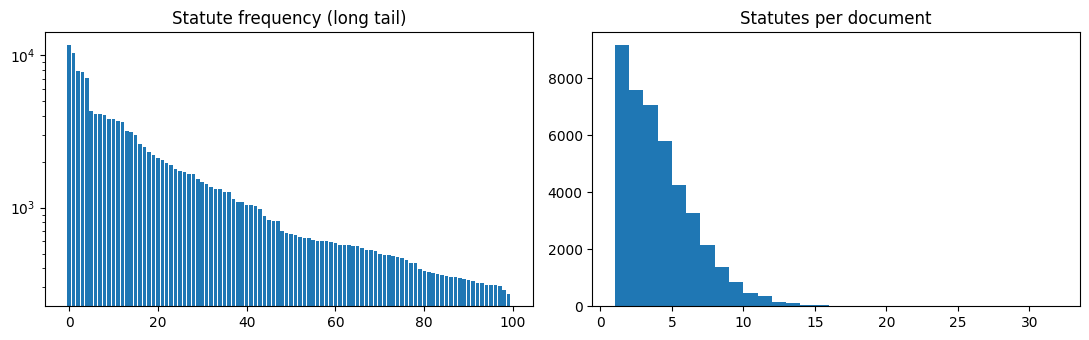

In [ ]:
# ═══ 3. data ═══
def _hf(fn): return hf_hub_download(HF_REPO, f"Phase_5_LSI/{fn}", repo_type="dataset", token=HF_TOKEN)
def _iter_json(path):
    import ijson                                               # stream the big json instead of loading it whole
    with open(path, "rb") as f: yield from ijson.items(f, "item")

CUE = re.compile(r"(?i)\b(sections?|sec\.|articles?|rules?|order|act|code|ipc|crpc|cpc)\b")
def select_text(text, mode):
    """headtail: start + end of the judgment | cue: start + sentences that cite sections/acts."""
    if len(text) <= MAX_CHARS: return text
    if mode == "cue":
        out, budget = [], MAX_CHARS - 2000
        for s in re.split(r"(?<=[.;])\s+", text[2000:]):
            if CUE.search(s) and (re.search(r"\d", s) or "Act" in s):
                out.append(s); budget -= len(s) + 1
                if budget <= 0: break
        return text[:2000] + "\n" + " ".join(out)
    h = MAX_CHARS // 4
    return text[:h] + "\n" + text[-(MAX_CHARS - h):]

def load_split(split, mode):
    cache = f"{P5_OUT}/cache/sel_{mode}_{split}.pkl"
    if os.path.exists(cache): return pickle.load(open(cache, "rb"))
    ids, texts, labels = [], [], []
    for d in tqdm(_iter_json(_hf(FILES[split])), desc=f"{split}/{mode}"):
        ids.append(str(d["id"])); texts.append(select_text(d["text"], mode)); labels.append([int(x) for x in (d.get("labels") or [])])
    out = dict(ids=ids, texts=texts, labels=labels); pickle.dump(out, open(cache, "wb")); return out

RAW = {s: load_split(s, "headtail") for s in FILES}
NUM_LABELS = 1 + max(l for s in ("train", "dev") for ls in RAW[s]["labels"] for l in ls)
def multihot(lists):
    Y = np.zeros((len(lists), NUM_LABELS), np.uint8)
    for i, ls in enumerate(lists): Y[i, ls] = 1
    return Y
Y_train, Y_dev = multihot(RAW["train"]["labels"]), multihot(RAW["dev"]["labels"]); TEST_IDS = RAW["test"]["ids"]; freq = Y_train.sum(0)

def rare_aware_subset(Y, n):
    print(len(Y))
    """Half of the subset = docs holding the rarest statutes (helps macro-F1), half random."""
    if n is None or n >= len(Y): return np.arange(len(Y))
    top = np.argsort(-(Y / Y.sum(0).clip(min=1)).sum(1))[: n // 2]; rest = np.setdiff1d(np.arange(len(Y)), top)
    return np.sort(np.concatenate([top, np.random.RandomState(SEED).choice(rest, n - len(top), replace=False)]))

print(f"docs train/dev/test = {len(Y_train)}/{len(Y_dev)}/{len(TEST_IDS)} | labels = {NUM_LABELS} | labels/doc = {Y_train.sum(1).mean():.2f}")
print(f"labels with <10 train docs: {(freq < 10).sum()} | unseen in train: {(freq == 0).sum()}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(range(NUM_LABELS), np.sort(freq)[::-1]); ax[0].set_yscale("log"); ax[0].set_title("Statute frequency (long tail)")
ax[1].hist(Y_train.sum(1), bins=range(1, int(Y_train.sum(1).max()) + 2)); ax[1].set_title("Statutes per document")
plt.tight_layout(); plt.savefig(f"{P5_OUT}/eda.png", dpi=130); plt.show()

In [ ]:
# !rm -rf /kaggle/working/phase5/cache/

In [ ]:
# ═══ 4. tokenise (parallel + cached), chunk batches, model, losses ═══
_TOK = None
def _enc(t): return np.asarray(_TOK.encode(clean_text(t)), dtype=np.int32)[: 8 * CHUNK_LEN]
def get_tokens(backbone, mode, split):
    global _TOK
    p = f"{P5_OUT}/cache/tok_{backbone}_{mode}_{split}.pkl"
    if os.path.exists(p): return pickle.load(open(p, "rb"))
    _TOK = TOKENIZERS[backbone]; texts = load_split(split, mode)["texts"]
    with get_context("fork").Pool(os.cpu_count()) as pool:     # workers inherit the tokenizer
        toks = list(tqdm(pool.imap(_enc, texts, chunksize=32), total=len(texts), desc=f"tok {backbone}/{split}"))
    pickle.dump(toks, open(p, "wb")); return toks

def pick_chunks(n_tok, n_chunks, mode):
    spans = [(s, min(s + CHUNK_LEN, n_tok)) for s in range(0, max(n_tok, 1), CHUNK_LEN)]
    if len(spans) <= n_chunks: return spans
    if mode == "cue": return spans[:n_chunks]                  # cue text is already condensed
    h = max(1, n_chunks // 4); return spans[:h] + spans[-(n_chunks - h):]   # headtail: start + end

def make_batch(toks_list, tok, n_chunks, mode):
    docs = [[[tok.bos_id] + t[s:e].tolist() + [tok.eos_id] for s, e in pick_chunks(len(t), n_chunks, mode)] for t in toks_list]
    B, C, L = len(docs), max(map(len, docs)), max(len(c) for d in docs for c in d)
    ids = torch.full((B, C, L), tok.pad_id, dtype=torch.long); mask = torch.zeros(B, C, dtype=torch.bool)
    for b, d in enumerate(docs):
        for c, seq in enumerate(d): ids[b, c, :len(seq)] = torch.tensor(seq); mask[b, c] = True
    return ids, mask

class LabelAttnHead(nn.Module):
    """Each statute attends over chunks with its own query -> its own document vector."""
    def __init__(self, d, n):
        super().__init__(); self.att = nn.Linear(d, n); self.w = nn.Parameter(torch.randn(n, d) * 0.02); self.bias = nn.Parameter(torch.zeros(n))
    def forward(self, grid, mask):
        a = self.att(grid).float().masked_fill(~mask[..., None], float("-inf")).softmax(1)
        return (torch.einsum("bcl,bcd->bld", a, grid.float()) * self.w).sum(-1) + self.bias

class LSIModel(nn.Module):
    def __init__(self, lm, n_labels, pool, tok, grad_ckpt, prior):
        super().__init__(); d = lm.wte.embedding_dim
        self.lm, self.pool_kind, self.pad_id, self.ckpt = lm, pool, tok.pad_id, grad_ckpt
        self.chunk_proj = nn.Sequential(nn.LayerNorm(2 * d), nn.Linear(2 * d, d), nn.GELU()); self.drop = nn.Dropout(0.1)
        if pool == "label_attn": self.head = LabelAttnHead(d, n_labels)
        else: self.pool = AttentionPooler(d) if pool == "attn" else MeanPooler(d); self.head = nn.Linear(d, n_labels)
        self.head.bias.data = torch.tensor(np.log(prior / (1 - prior)), dtype=torch.float32)   # start from label priors
    def forward(self, ids, cmask):                             # ids (B,C,L), cmask (B,C)
        B, C, L = ids.shape; flat = ids[cmask]                 # only real chunks go through the LM
        h = run_blocks(self.lm, self.lm.wte(flat), self.ckpt).float()
        m = flat.ne(self.pad_id); w = m.unsqueeze(-1).float()
        mean = (h * w).sum(1) / w.sum(1).clamp(min=1); last = h[torch.arange(flat.size(0), device=flat.device), m.sum(1) - 1]
        vec = self.chunk_proj(torch.cat([mean, last], -1))
        grid = vec.new_zeros(B, C, vec.size(-1)); grid[cmask] = vec; grid = self.drop(grid)
        return self.head(grid, cmask) if self.pool_kind == "label_attn" else self.head(self.drop(self.pool(grid, cmask)))

@dataclass
class LSIExp:
    name: str; backbone: str; method: str          # full | partial | lorma | adalora | adapter
    pool: str = "attn"                             # mean | attn | label_attn
    mode: str = "headtail"                         # headtail | cue
    n_chunks: int = 4
    loss: str = "wbce"                             # bce | wbce | asl
    epochs: int = 2; lr: float = 3e-4; head_lr: float = 2e-3
    batch_docs: int = 4; grad_accum: int = 4
    rank: int = 16; alpha: float = 32.0; n_top: int = 2; adapter_dim: int = 64; final_ratio: float = 0.5
    keep_every: int = 1                            # KD student: keep every k-th block
    teacher: str = None; kd_T: float = 2.0; kd_w: float = 0.5
    grad_ckpt: bool = False; train_docs: int = TRAIN_DOCS

def lsi_build(e):
    lm = _loaders[e.backbone](CKPTS[e.backbone]); tok = TOKENIZERS[e.backbone]
    assert lm.wte.weight.shape[0] == tok.vocab_size, "tokenizer/checkpoint vocab mismatch"
    if e.keep_every > 1: lm.blocks = nn.ModuleList(list(lm.blocks)[::e.keep_every])
    for p in lm.parameters(): p.requires_grad = (e.method == "full")
    if e.method == "partial":
        for b in lm.blocks[-e.n_top:]:
            for p in b.parameters(): p.requires_grad = True
        for p in lm.ln_f.parameters(): p.requires_grad = True
    elif e.method == "lorma":   wrap_linears(lm.blocks, lambda l: LoRMA(l, e.rank, e.alpha), PEFT_TARGETS[e.backbone])
    elif e.method == "adalora": wrap_linears(lm.blocks, lambda l: AdaLoRA(l, e.rank, e.alpha), PEFT_TARGETS[e.backbone])
    elif e.method == "adapter":
        d = lm.wte.embedding_dim; lm.blocks = nn.ModuleList([AdapterBlock(b, d, e.adapter_dim) for b in lm.blocks])
    elif e.method != "full": raise ValueError(e.method)
    return LSIModel(lm, NUM_LABELS, e.pool, tok, e.grad_ckpt, Y_train.mean(0).clip(1e-4, 0.5)).to(DEVICE)

def pos_weight():
    pos = Y_train.sum(0).clip(min=1); return torch.tensor(np.sqrt((len(Y_train) - pos) / pos).clip(1, 30), dtype=torch.float32, device=DEVICE)

def lsi_loss(z, y, kind, pw):
    y = y.float()
    if kind == "bce":  return F.binary_cross_entropy_with_logits(z, y)
    if kind == "wbce": return F.binary_cross_entropy_with_logits(z, y, pos_weight=pw)      # rare statutes weighted up
    if kind == "asl":                                          # asymmetric loss: easy negatives down-weighted
        p = torch.sigmoid(z); pn = (p - 0.05).clamp(min=0)
        return -(y * torch.log(p.clamp(min=1e-8)) * (1 - p) + (1 - y) * torch.log((1 - pn).clamp(min=1e-8)) * pn ** 4).sum(1).mean()
    raise ValueError(kind)

In [ ]:
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
# --- 1. Phase 5 Dataset & DataLoader Helpers ---
class LSIDataset(Dataset):
    def __init__(self, toks_list, labels, mode="headtail", n_chunks=4):
        self.toks_list = toks_list
        self.labels = labels  # Multi-hot numpy matrix (N, L)
        self.mode = mode
        self.n_chunks = n_chunks

    def __len__(self):
        return len(self.toks_list)

    def __getitem__(self, idx):
        return self.toks_list[idx], self.labels[idx]

def lsi_collate_fn(batch):
    toks_batch, labels_batch = zip(*batch)

    # Fallback to global `tokenizer` if `_TOK` hasn't been set in this scope
    active_tok = _TOK if _TOK is not None else tokenizer

    # Use make_batch with the verified active tokenizer
    ids, mask = make_batch(toks_batch, active_tok, n_chunks=4, mode="headtail")
    y = torch.tensor(np.array(labels_batch), dtype=torch.float32)
    return ids, mask, y


# --- 2. Instantiate Phase 5 DataLoaders ---
# Assuming you load your train, dev/val, and test text splits via Phase 5 files:
# (e.g., train_toks = get_tokens(BACKBONE, "headtail", "train"))
# 1. Generate / load token caches for train, dev (validation), and test splits
train_toks = get_tokens(BACKBONE, "headtail", "train")
val_toks   = get_tokens(BACKBONE, "headtail", "dev")
test_toks  = get_tokens(BACKBONE, "headtail", "test")

# 2. Instantiate Phase 5 Datasets using the generated token lists
train_dataset = LSIDataset(train_toks, Y_train, mode="headtail", n_chunks=4)
val_dataset   = LSIDataset(val_toks, Y_dev, mode="headtail", n_chunks=4)   # Note: using Y_dev instead of Y_val
test_dataset  = LSIDataset(test_toks, np.zeros((len(test_toks), NUM_LABELS)), mode="headtail", n_chunks=4)

# 3. Create your DataLoaders
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, collate_fn=lsi_collate_fn)
val_loader   = DataLoader(val_dataset, batch_size=4, shuffle=False, collate_fn=lsi_collate_fn)
test_loader  = DataLoader(test_dataset, batch_size=4, shuffle=False, collate_fn=lsi_collate_fn)

print("DataLoaders initialized successfully!")

DataLoaders initialized successfully!


In [ ]:
# ═══ 5. inference + thresholds + metrics ═══
@torch.no_grad()
def lsi_predict(model, toks, tok, e, bs=8):
    model.eval(); order = np.argsort([len(t) for t in toks]); out = []          # length-sorted -> less padding
    for i in range(0, len(order), bs):
        ids, cm = make_batch([toks[j] for j in order[i:i + bs]], tok, e.n_chunks, e.mode)
        with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            out.append(torch.sigmoid(model(ids.to(DEVICE), cm.to(DEVICE)).float()).cpu())
    P = torch.cat(out).numpy(); res = np.empty_like(P); res[order] = P; return res

def to_pred(P, thr):
    pred = P >= thr                                            # thr: scalar (global) or vector (per-label)
    empty = ~pred.any(1); pred[empty, P[empty].argmax(1)] = True               # every doc gets >=1 statute
    return pred.astype(np.uint8)

def score(Y, P, thr):
    pr = to_pred(P, thr); has = Y.sum(0) > 0
    return dict(macro=f1_score(Y, pr, average="macro", zero_division=0), macro_present=f1_score(Y[:, has], pr[:, has], average="macro", zero_division=0),
                micro=f1_score(Y, pr, average="micro", zero_division=0), subset=float((pr == Y).all(1).mean()))

def tune(P, Y, grid=np.arange(0.05, 0.9, 0.025), min_pos=5, shrink=0.5):
    """Global threshold + per-label thresholds (shrunk towards the global one to limit dev overfitting)."""
    g = grid[int(np.argmax([f1_score(Y, (P >= t).astype(int), average="macro", zero_division=0) for t in grid]))]
    thr = np.full(Y.shape[1], g)
    for j in range(Y.shape[1]):
        if Y[:, j].sum() < min_pos: continue                   # too few positives -> keep global
        pred = P[:, j, None] >= grid; tp = (pred & (Y[:, j, None] == 1)).sum(0); fp = pred.sum(0) - tp; fn = Y[:, j].sum() - tp
        thr[j] = shrink * grid[(2 * tp / np.maximum(2 * tp + fp + fn, 1)).argmax()] + (1 - shrink) * g
    return float(g), thr

def honest_cv(P, Y):
    """Tune on one dev half, score on the other (and swap): a less optimistic macro-F1."""
    idx = np.random.RandomState(0).permutation(len(Y)); a, b = np.array_split(idx, 2); out = []
    for tr, te in ((a, b), (b, a)):
        g, t = tune(P[tr], Y[tr]); out.append((score(Y[te], P[te], g)["macro"], score(Y[te], P[te], t)["macro"]))
    return tuple(np.mean(out, 0))

def write_submission(P, thr, name):
    pr = to_pred(P, thr); sub = [{"id": i, "pred": [int(x) for x in np.flatnonzero(r)]} for i, r in zip(TEST_IDS, pr)]
    assert len(sub) == len(TEST_IDS)
    folder = f"{P5_OUT}/submissions/{name}"; os.makedirs(folder, exist_ok=True)
    json.dump(sub, open(f"{folder}/prediction.json", "w"))
    with zipfile.ZipFile(f"{folder}/submission.zip", "w", zipfile.ZIP_DEFLATED) as z: z.write(f"{folder}/prediction.json", arcname="prediction.json")

In [ ]:
# ═══ 6. training + experiment runner ═══
from tqdm.auto import tqdm
def _save(obj, path): torch.save(obj, path + ".tmp"); os.replace(path + ".tmp", path)
def trainable_state(model, full):
    sd = model.state_dict()
    keys = set(sd) if full else {n for n, p in model.named_parameters() if p.requires_grad} | {k for k in sd if k.endswith(".mask")}
    return {k: sd[k].detach().cpu() for k in keys}

def lsi_load_teacher(name):
    """Teacher = a finished experiment. It gets ITS OWN tokenisation of the same docs (vocabs differ across backbones)."""
    te = LSIExp(**json.load(open(f"{P5_OUT}/result_{name}.json"))["config"])
    m = lsi_build(te); m.load_state_dict(torch.load(f"{P5_OUT}/ckpt/{name}_best.pt", weights_only=False)["state"], strict=False)
    for p in m.parameters(): p.requires_grad = False
    return dict(model=m.eval(), exp=te, tok=TOKENIZERS[te.backbone], toks=get_tokens(te.backbone, te.mode, "train"))

def lsi_train(e, model, teacher, tok, tr_toks, rows, dv_toks):
    ck, best_p = f"{P5_OUT}/ckpt/{e.name}_latest.pt", f"{P5_OUT}/ckpt/{e.name}_best.pt"
    full, pw = e.method == "full", pos_weight()
    body = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith("lm.")]
    head = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith("lm.")]
    opt = torch.optim.AdamW([dict(params=body, lr=e.lr, weight_decay=0.01), dict(params=head, lr=e.head_lr, weight_decay=0.0)]); base = [e.lr, e.head_lr]
    mpe = max(1, min(e.train_docs, len(rows)) // e.batch_docs // e.grad_accum) * e.grad_accum   # micro-batches per epoch
    total_steps = e.epochs * mpe // e.grad_accum; warm = max(1, int(0.06 * total_steps))
    pruner = AdaLoRAPruner(model, total_steps, e.final_ratio, **ADALORA_CFG) if e.method == "adalora" else None
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)

    micro, best, hist = 0, -1.0, dict(loss=[], f1=[], train_sec=0.0)
    if os.path.exists(ck):                                     # resume, even mid-epoch
        s = torch.load(ck, map_location="cpu", weights_only=False)
        model.load_state_dict(s["model"], strict=False); opt.load_state_dict(s["opt"]); scaler.load_state_dict(s["scaler"])
        if pruner and s["imp"]:
            for a, b in zip(pruner.importance, s["imp"]): a.copy_(b)
        micro, best, hist = s["micro"], s["best"], s["hist"]; print(f"[{e.name}] resumed at step {micro // e.grad_accum}/{total_steps}")
    def save_ck():
        _save(dict(model=trainable_state(model, full), opt=opt.state_dict(), scaler=scaler.state_dict(), micro=micro, best=best, hist=hist,
                   imp=None if pruner is None else [i.cpu() for i in pruner.importance]), ck)

    sec0, t0 = hist["train_sec"], time.time()
    for ep in tqdm(range(micro // mpe, e.epochs)):
        order = np.random.RandomState(SEED + ep).permutation(rows)[: mpe * e.batch_docs]   # deterministic order -> resumable
        model.train(); run, n = 0.0, 0
        for i in tqdm(range(micro - ep * mpe, mpe)):
            sel = order[i * e.batch_docs:(i + 1) * e.batch_docs]
            ids, cm = make_batch([tr_toks[j] for j in sel], tok, e.n_chunks, e.mode); y = torch.from_numpy(Y_train[sel]).to(DEVICE)
            with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                z = model(ids.to(DEVICE), cm.to(DEVICE)).float()
                if teacher:
                    t_ids, t_cm = make_batch([teacher["toks"][j] for j in sel], teacher["tok"], teacher["exp"].n_chunks, teacher["exp"].mode)
                    with torch.no_grad(): tz = teacher["model"](t_ids.to(DEVICE), t_cm.to(DEVICE)).float()
            loss = lsi_loss(z, y, e.loss, pw)
            if teacher:                                        # distill: match the teacher's temperature-softened probabilities
                soft = F.binary_cross_entropy_with_logits(z / e.kd_T, torch.sigmoid(tz / e.kd_T)) * e.kd_T ** 2
                loss = e.kd_w * loss + (1 - e.kd_w) * soft
            if pruner: loss = loss + 0.1 * pruner.orth_loss()
            scaler.scale(loss / e.grad_accum).backward(); micro += 1; run += loss.item(); n += 1
            if micro % e.grad_accum == 0:
                step = micro // e.grad_accum
                f = step / warm if step <= warm else 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total_steps - warm)))
                for g, b in zip(opt.param_groups, base): g["lr"] = b * f
                scaler.unscale_(opt); gn = torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
                if pruner and torch.isfinite(gn): pruner.update(step - 1)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
                # Print evaluation score every 20 steps
                if step % 20 == 0:
                    model.eval()
                    with torch.no_grad():
                        # Quick dev evaluation on a small subset or full dev set
                        Pd_sample = lsi_predict(model, dv_toks[:64], tok, e) # evaluated on a subset for speed every 20 steps
                        g_sample, _ = tune(Pd_sample, Y_dev[:64], min_pos=10**9)
                        step_f1 = score(Y_dev[:64], Pd_sample, g_sample)["macro"]
                    model.train()
                    print(f"[{e.name}] Step {step}/{total_steps} | Running Loss: {run / n:.4f} | Quick Dev macro-F1: {step_f1:.4f}")
                if step % CKPT_EVERY == 0:
                    hist["train_sec"] = sec0 + time.time() - t0; save_ck(); print(f"[{e.name}] step {step}/{total_steps} loss {run / n:.4f} (ckpt saved)")
        # end of epoch: quick dev check with a global threshold (model selection)
        P = lsi_predict(model, dv_toks, tok, e); g, _ = tune(P, Y_dev, min_pos=10 ** 9); f1 = score(Y_dev, P, g)["macro"]
        hist["loss"].append(run / max(n, 1)); hist["f1"].append(f1); hist["train_sec"] = sec0 + time.time() - t0
        print(f"[{e.name}] epoch {ep + 1}/{e.epochs} loss {run / max(n, 1):.4f} | dev macro-F1 {f1:.4f} @thr {g:.2f}")
        if f1 > best: best = f1; _save(dict(state=trainable_state(model, full)), best_p)
        save_ck()
    model.load_state_dict(torch.load(best_p, map_location="cpu", weights_only=False)["state"], strict=False)
    return hist

def lsi_run(e):
    rf = f"{P5_OUT}/result_{e.name}.json"
    print(rf)
    if os.path.exists(rf): print(f"[{e.name}] done earlier, skipped"); return json.load(open(rf))
    seed_all(); tok = TOKENIZERS[e.backbone]
    tr, dv, te_ = (get_tokens(e.backbone, e.mode, s) for s in ("train", "dev", "test"))
    rows = rare_aware_subset(Y_train, e.train_docs)
    print(f"\n=== {e.name} | {e.backbone} | {e.method} | pool={e.pool} mode={e.mode} chunks={e.n_chunks} loss={e.loss}" + (f" | KD<-{e.teacher}" if e.teacher else "") + " ===")
    model = lsi_build(e); teacher = lsi_load_teacher(e.teacher) if e.teacher else None
    total = sum(p.numel() for p in model.parameters()) / 1e6; trn = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
    print(f"params {total:.1f}M total, {trn:.2f}M trainable")
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    hist = lsi_train(e, model, teacher, tok, tr, rows, dv)
    peak = torch.cuda.max_memory_allocated() / 2 ** 30 if DEVICE.type == "cuda" else float("nan")

    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter(); Pd = lsi_predict(model, dv, tok, e)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    ms = (time.perf_counter() - t0) / len(dv) * 1000; Pt = lsi_predict(model, te_, tok, e)

    g, thr = tune(Pd, Y_dev); h_g, h_l = honest_cv(Pd, Y_dev)
    use = "label" if h_l > h_g else "global"; thr_used = thr if use == "label" else g     # choose by the honest score
    sc = score(Y_dev, Pd, thr_used)
    np.save(f"{P5_OUT}/dev_{e.name}.npy", Pd); np.save(f"{P5_OUT}/test_{e.name}.npy", Pt); np.save(f"{P5_OUT}/thr_{e.name}.npy", np.broadcast_to(thr_used, NUM_LABELS))
    write_submission(Pt, thr_used, e.name)
    res = dict(name=e.name, config=asdict(e), total_M=total, trainable_M=trn, size_MB=total * 4, train_min=hist["train_sec"] / 60, ms_per_doc=ms, peak_GB=peak,
               thr_mode=use, g=g, F1_global=score(Y_dev, Pd, g)["macro"], F1_label=score(Y_dev, Pd, thr)["macro"], honest_global=h_g, honest_label=h_l,
               F1_at_0p5=score(Y_dev, Pd, 0.5)["macro"], **sc, hist=hist)
    json.dump(res, open(rf, "w"), indent=1, default=float)
    print(f"-> {e.name}: macro-F1 {sc['macro']:.4f} (honest {max(h_g, h_l):.4f}, {use} thr) | micro {sc['micro']:.4f} | subset {sc['subset']:.4f} | {res['train_min']:.1f} min | {ms:.0f} ms/doc | {peak:.1f} GB")
    del model, teacher; gc.collect(); torch.cuda.empty_cache(); return res

In [ ]:
# !find /kaggle/working/phase5/ -type f -name '*exp2*' -print -delete
# !rm -f /kaggle/working/phase5/ckpt/exp1_lorma_custom_mha_latest.pt
# !rm -f /kaggle/working/phase5/ckpt/exp1_lorma_custom_mha_best.pt

In [ ]:
res_gqa_conv = lsi_run(LSIExp("exp2_full_gqa_conv", "gqa_conv", "full", lr=3e-5, head_lr=1e-3, epochs=1, batch_docs=4, grad_accum=4, grad_ckpt=True))

/kaggle/working/phase5/result_exp2_full_gqa_conv.json
[exp2_full_gqa_conv] done earlier, skipped


In [ ]:
# ═══ 7. required experiments (exp2 first: it is the KD teacher for exp4) ═══
REQUIRED = [
    LSIExp("exp2_full_gqa_conv", "gqa_conv", "full", lr=3e-5, head_lr=1e-3, epochs=2, batch_docs=2, grad_accum=8, grad_ckpt=True),
    LSIExp("exp1_lorma_custom_mha", "custom_mha", "lorma", lr=3e-4, epochs=1),
    LSIExp("exp3_adalora_mla_moe", "mla_moe", "adalora", lr=5e-4, rank=12, alpha=24.0, epochs=1),
    # KD student: gqa_alibi with every 2nd block (12 -> 6 layers), distilled from the fully fine-tuned gqa_conv teacher
    LSIExp("exp4_kd_gqa_alibi_half", "gqa_alibi", "full", lr=5e-5, head_lr=1e-3, epochs=1, batch_docs=2, grad_accum=8,
           grad_ckpt=True, keep_every=2, teacher="exp2_full_gqa_conv"),
]
for e in REQUIRED: lsi_run(e)

/kaggle/working/phase5/result_exp2_full_gqa_conv.json
[exp2_full_gqa_conv] done earlier, skipped
/kaggle/working/phase5/result_exp1_lorma_custom_mha.json
[exp1_lorma_custom_mha] done earlier, skipped
/kaggle/working/phase5/result_exp3_adalora_mla_moe.json
[exp3_adalora_mla_moe] done earlier, skipped
/kaggle/working/phase5/result_exp4_kd_gqa_alibi_half.json
[exp4_kd_gqa_alibi_half] done earlier, skipped


                  name   backbone  method  macro_F1  honest_F1  F1_global  F1_label  micro_F1  subset_acc   thr  total_M  trainable_M  train_min  ms_per_doc  peak_GB
    exp2_full_gqa_conv   gqa_conv    full    0.3142     0.3108     0.3028    0.3142    0.4243      0.0203 label  79.3962      79.3962   238.3930     77.4128   6.6390
exp4_kd_gqa_alibi_half  gqa_alibi    full    0.2319     0.2295     0.2144    0.2319    0.3180      0.0043 label  64.7755      64.7755    41.3186     54.9811   3.9310
  exp3_adalora_mla_moe    mla_moe adalora    0.1670     0.1658     0.1516    0.1670    0.2481      0.0017 label 101.7765       1.7126    32.1790     70.3288  11.2480
 exp1_lorma_custom_mha custom_mha   lorma    0.1627     0.1621     0.1453    0.1627    0.2507      0.0010 label  77.9027       2.8345    35.0676     82.5028   6.1805


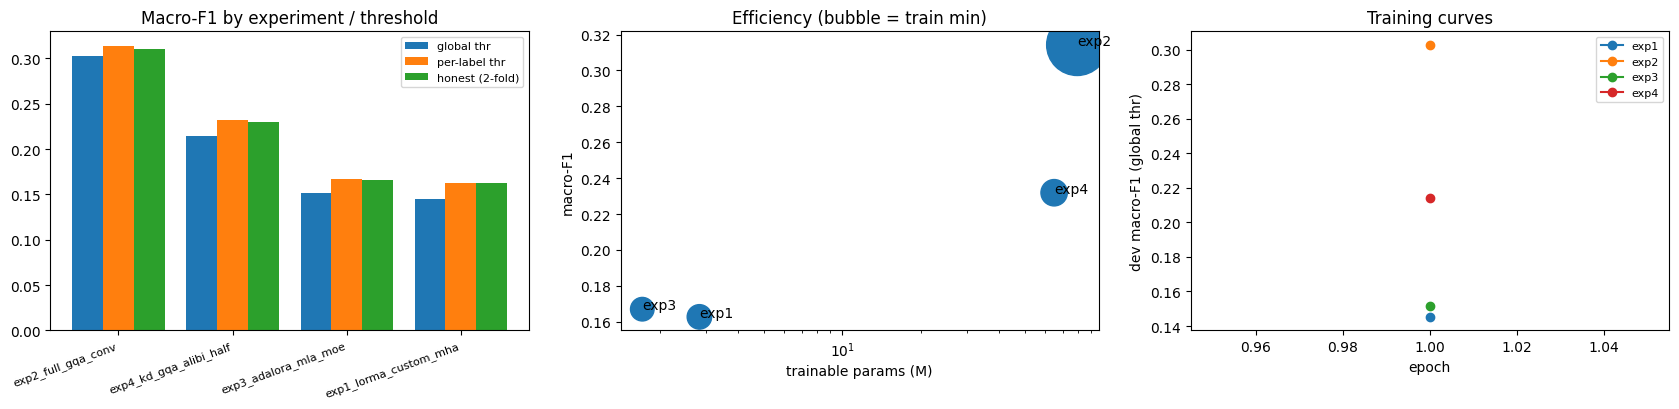

In [ ]:
# ═══ 8. results + plots ═══
def load_results(prefix=""):
    return [json.load(open(f"{P5_OUT}/{f}")) for f in sorted(os.listdir(P5_OUT)) if f.startswith("result_" + prefix) and f.endswith(".json")]

R = load_results("exp")
df = pd.DataFrame([dict(name=r["name"], backbone=r["config"]["backbone"], method=r["config"]["method"], macro_F1=r["macro"],
                        honest_F1=max(r["honest_global"], r["honest_label"]), F1_global=r["F1_global"], F1_label=r["F1_label"],
                        micro_F1=r["micro"], subset_acc=r["subset"], thr=r["thr_mode"], total_M=r["total_M"], trainable_M=r["trainable_M"],
                        train_min=r["train_min"], ms_per_doc=r["ms_per_doc"], peak_GB=r["peak_GB"]) for r in R]).sort_values("macro_F1", ascending=False)
print(df.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2)); x = np.arange(len(df)); w = 0.27
ax[0].bar(x - w, df.F1_global, w, label="global thr"); ax[0].bar(x, df.F1_label, w, label="per-label thr"); ax[0].bar(x + w, df.honest_F1, w, label="honest (2-fold)")
ax[0].set_xticks(x); ax[0].set_xticklabels(df.name, rotation=20, ha="right", fontsize=8); ax[0].set_title("Macro-F1 by experiment / threshold"); ax[0].legend(fontsize=8)
ax[1].scatter(df.trainable_M, df.macro_F1, s=df.train_min * 8 + 30)
for _, r in df.iterrows(): ax[1].annotate(r["name"].split("_")[0], (r.trainable_M, r.macro_F1))
ax[1].set_xscale("log"); ax[1].set_xlabel("trainable params (M)"); ax[1].set_ylabel("macro-F1"); ax[1].set_title("Efficiency (bubble = train min)")
for r in R: ax[2].plot(range(1, len(r["hist"]["f1"]) + 1), r["hist"]["f1"], marker="o", label=r["name"].split("_")[0])
ax[2].set_xlabel("epoch"); ax[2].set_ylabel("dev macro-F1 (global thr)"); ax[2].set_title("Training curves"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{P5_OUT}/results_overview.png", dpi=130); plt.show()

os.makedirs(f"{P5_OUT}/final_submissions", exist_ok=True)          # the 4 official zips in one folder
for n in df.name: shutil.copy(f"{P5_OUT}/submissions/{n}/submission.zip", f"{P5_OUT}/final_submissions/{n}.zip")

In [ ]:
# Run this in a code cell to remove the corrupted file and re-run exp3
# !rm -f /kaggle/working/phase5/dev_exp3_adalora_mla_moe.npy
# !rm -f /kaggle/working/phase5/test_exp3_adalora_mla_moe.npy
# !rm -f /kaggle/working/phase5/thr_exp3_adalora_mla_moe.npy
# !rm -f /kaggle/working/phase5/result_exp3_adalora_mla_moe.json

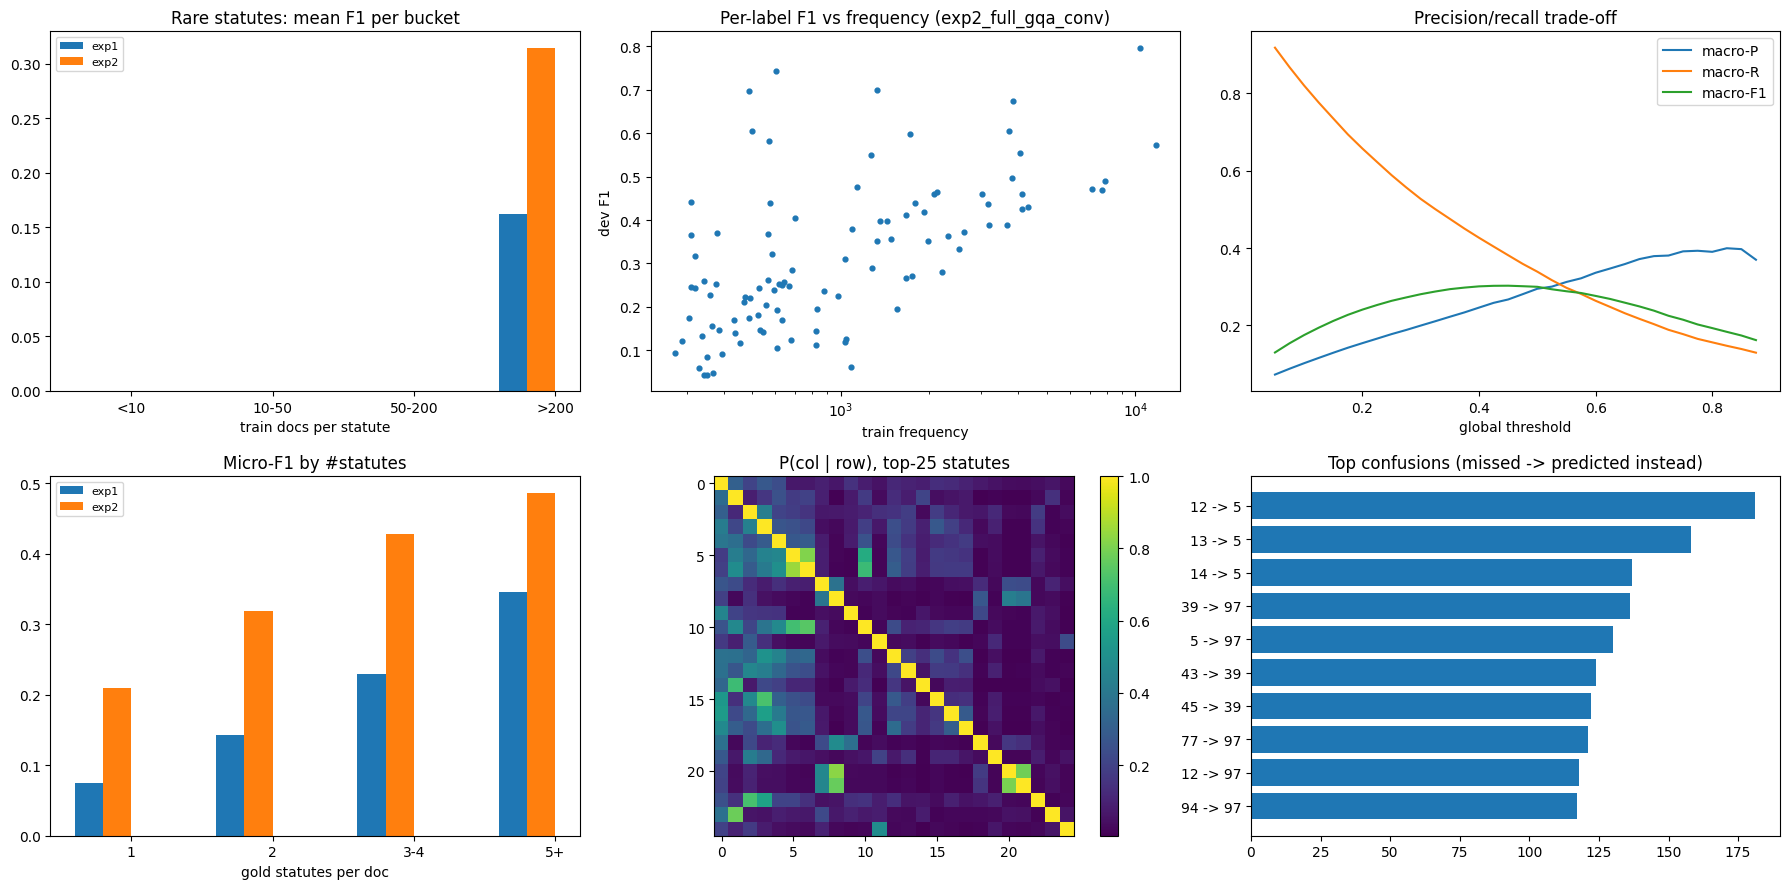

Weakest statutes (id, dev support, F1): [(0, 86, 0.04), (8, 92, 0.04), (2, 98, 0.05), (27, 83, 0.06), (52, 272, 0.06), (65, 105, 0.08), (18, 100, 0.09), (84, 68, 0.09), (82, 156, 0.1), (41, 205, 0.11)]


In [ ]:
# ═══ 9. deeper analysis (Robust Loader) ═══
def per_label_f1(Y, pr):
    tp = (Y & pr).sum(0)
    return 2 * tp / np.maximum(2 * tp + (pr.sum(0) - tp) + (Y.sum(0) - tp), 1)

DEVP = {}
for r in R:
    name = r["name"]
    if name in ("exp3_adalora_mla_moe", "exp4_kd_gqa_alibi_half"): continue
    # print(name)
    path = f"{P5_OUT}/dev_{name}.npy"
    arr = np.load(path)

    # Safeguard: if the array got flattened or has a mismatched shape,
    # try to reshape it dynamically if total size matches (10181 docs, 100 labels)
    if arr.size == len(Y_dev) * NUM_LABELS and arr.shape != (len(Y_dev), NUM_LABELS):
        arr = arr.reshape(len(Y_dev), NUM_LABELS)
    elif arr.shape != (len(Y_dev), NUM_LABELS):
        print(f"WARNING: Skipping {name} due to unexpected shape {arr.shape} (expected {(len(Y_dev), NUM_LABELS)})")
        continue

    DEVP[name] = arr

# Filter DataFrame `df` and list `R` to only include models that loaded successfully
valid_names = set(DEVP.keys())
R = [r for r in R if r["name"] in valid_names]
df = df[df["name"].isin(valid_names)].reset_index(drop=True)

PREDS = {n: to_pred(DEVP[n], np.load(f"{P5_OUT}/thr_{n}.npy")) for n in DEVP}
best = df.iloc[0]["name"]
has = Y_dev.sum(0) > 0

fig, ax = plt.subplots(2, 3, figsize=(18, 9))

# (a) rare vs frequent statutes: mean per-label F1 per train-frequency bucket
edges, labs = [0, 10, 50, 200, 10 ** 9], ["<10", "10-50", "50-200", ">200"]
for k, n in enumerate(PREDS):
    f = per_label_f1(Y_dev, PREDS[n])
    ax[0, 0].bar(np.arange(4) + k * 0.2, [f[has & (freq >= a) & (freq < b)].mean() if (has & (freq >= a) & (freq < b)).any() else 0 for a, b in zip(edges[:-1], edges[1:])], 0.2, label=n.split("_")[0])
ax[0, 0].set_xticks(np.arange(4) + 0.3); ax[0, 0].set_xticklabels(labs); ax[0, 0].set_xlabel("train docs per statute"); ax[0, 0].set_title("Rare statutes: mean F1 per bucket"); ax[0, 0].legend(fontsize=8)

# (b) F1 vs frequency (best model)
ax[0, 1].scatter(freq[has] + 1, per_label_f1(Y_dev, PREDS[best])[has], s=12); ax[0, 1].set_xscale("log")
ax[0, 1].set_xlabel("train frequency"); ax[0, 1].set_ylabel("dev F1"); ax[0, 1].set_title(f"Per-label F1 vs frequency ({best})")

# (c) precision / recall / macro-F1 vs global threshold
P = DEVP[best]; ts = np.arange(0.05, 0.9, 0.025); pr_, rc_, f_ = [], [], []
for t in ts:
    pr = to_pred(P, t); tp = (pr & Y_dev).sum(0)
    pr_.append(np.mean(tp / np.maximum(pr.sum(0), 1)))
    rc_.append(np.mean(tp / np.maximum(Y_dev.sum(0), 1)))
    f_.append(f1_score(Y_dev, pr, average="macro", zero_division=0))
ax[0, 2].plot(ts, pr_, label="macro-P"); ax[0, 2].plot(ts, rc_, label="macro-R"); ax[0, 2].plot(ts, f_, label="macro-F1"); ax[0, 2].legend(); ax[0, 2].set_xlabel("global threshold"); ax[0, 2].set_title("Precision/recall trade-off")

# (d) micro-F1 by number of gold statutes per doc
nl = Y_dev.sum(1); bins = [(1, 1), (2, 2), (3, 4), (5, 999)]
for k, n in enumerate(PREDS):
    ax[1, 0].bar(np.arange(4) + k * 0.2, [f1_score(Y_dev[(nl >= a) & (nl <= b)], PREDS[n][(nl >= a) & (nl <= b)], average="micro", zero_division=0) if ((nl >= a) & (nl <= b)).any() else 0 for a, b in bins], 0.2, label=n.split("_")[0])
ax[1, 0].set_xticks(np.arange(4) + 0.3); ax[1, 0].set_xticklabels(["1", "2", "3-4", "5+"]); ax[1, 0].set_xlabel("gold statutes per doc"); ax[1, 0].set_title("Micro-F1 by #statutes"); ax[1, 0].legend(fontsize=8)

# (e) co-occurrence of the 25 most frequent statutes
top = np.argsort(-freq)[:25]; co = (Y_train[:, top].T.astype(float) @ Y_train[:, top]) / freq[top][:, None].clip(min=1)
im = ax[1, 1].imshow(co, cmap="viridis"); ax[1, 1].set_title("P(col | row), top-25 statutes"); plt.colorbar(im, ax=ax[1, 1])

# (f) most common confusions: gold statute missed while another one was predicted wrongly
miss = (Y_dev & (1 - PREDS[best])).astype(int); wrong = ((1 - Y_dev) & PREDS[best]).astype(int)
C = miss.T @ wrong; np.fill_diagonal(C, 0); idx = np.dstack(np.unravel_index(np.argsort(-C.ravel())[:10], C.shape))[0]
ax[1, 2].barh([f"{a} -> {b}" for a, b in idx][::-1], [C[a, b] for a, b in idx][::-1]); ax[1, 2].set_title("Top confusions (missed -> predicted instead)")

plt.tight_layout(); plt.savefig(f"{P5_OUT}/label_analysis.png", dpi=130); plt.show()

f = per_label_f1(Y_dev, PREDS[best]); worst = np.argsort(f + (~has) * 9)[:10]
print("Weakest statutes (id, dev support, F1):", [(int(j), int(Y_dev[:, j].sum()), round(float(f[j]), 2)) for j in worst])

In [ ]:
# # ═══════════════════════════════════════════════════════════════
# #  Threshold tuning + final prediction / submission
# #  (global + per-label, pick best by macro-F1 on val)
# # ═══════════════════════════════════════════════════════════════
# import numpy as np
# from sklearn.metrics import f1_score
# from pathlib import Path
# import zipfile, json, shutil

# def tune_global_threshold(y_true, y_prob, thresholds=None):
#     """Single threshold for all labels. Returns best_thr, best_macro_f1."""
#     if thresholds is None:
#         thresholds = np.linspace(0.05, 0.95, 37)  # denser near typical values
#     best_f1, best_thr = -1.0, 0.5
#     for t in thresholds:
#         pred = (y_prob >= t).astype(np.int32)
#         f1 = f1_score(y_true, pred, average="macro", zero_division=0)
#         if f1 > best_f1:
#             best_f1, best_thr = f1, t
#     return best_thr, best_f1

# def tune_per_label_thresholds(y_true, y_prob, thresholds=None):
#     """Independent threshold per label. Returns array of thresholds + macro-F1."""
#     if thresholds is None:
#         thresholds = np.linspace(0.05, 0.95, 37)
#     n_labels = y_true.shape[1]
#     best_thrs = np.full(n_labels, 0.5)
#     for j in range(n_labels):
#         best_f1_j = -1.0
#         for t in thresholds:
#             pred_j = (y_prob[:, j] >= t).astype(np.int32)
#             f1_j = f1_score(y_true[:, j], pred_j, zero_division=0)
#             if f1_j > best_f1_j:
#                 best_f1_j = f1_j
#                 best_thrs[j] = t
#     # evaluate the vector of thresholds
#     pred = (y_prob >= best_thrs[None, :]).astype(np.int32)
#     macro = f1_score(y_true, pred, average="macro", zero_division=0)
#     return best_thrs, macro

# def apply_thresholds(y_prob, thr):
#     """thr can be a scalar (global) or a 1-D array (per-label)."""
#     if np.isscalar(thr) or thr.ndim == 0:
#         return (y_prob >= thr).astype(np.int32)
#     return (y_prob >= thr[None, :]).astype(np.int32)

# def make_submission(pred_matrix, doc_ids, label_names, out_dir, exp_name):
#     """
#     pred_matrix : (N, L) binary
#     Saves the official JSON submission format + a zip.
#     """
#     out_dir = Path(out_dir)
#     out_dir.mkdir(parents=True, exist_ok=True)

#     # Use submission_{exp_name} directory structure
#     sub_dir = out_dir / f"submission_{exp_name}"
#     sub_dir.mkdir(exist_ok=True, parents=True)

#     # Build dictionary mapping document ID -> list of predicted label strings
#     out = {}
#     for i, doc_id in enumerate(doc_ids):
#         # Find all indices where prediction is 1 and map to label name
#         preds = [label_names[j] for j, val in enumerate(pred_matrix[i]) if val == 1]
#         out[str(doc_id)] = preds

#     pred_path = sub_dir / "prediction.json"
#     with open(pred_path, "w", encoding="utf-8") as f:
#         json.dump(out, f, ensure_ascii=False, indent=1)

#     # Also save the raw binary matrix for later analysis
#     np.save(sub_dir / "pred_matrix.npy", pred_matrix)

#     zip_path = sub_dir / "submission_tuned.zip"
#     with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
#         zf.write(pred_path, arcname="prediction.json")

#     print(f"  → submission saved: {zip_path} | {len(out)} docs")
#     return zip_path

# # ─── main routine: run for every previously trained experiment ───
# def retune_and_submit(exp_names,
#                       val_probs, val_true,          # dict[exp_name] → (N,L)
#                       test_probs, test_doc_ids,     # dict[exp_name] → (N,L) and list of ids
#                       label_names,
#                       out_root=f"{P5_OUT}/retuned_submissions"):
#     """
#     exp_names      : list of experiment names you already trained
#     val_probs      : {name: np.array (N_val, L)}
#     val_true       : {name: np.array (N_val, L)}   (same for all if shared val set)
#     test_probs     : {name: np.array (N_test, L)}
#     test_doc_ids   : list or {name: list}
#     """
#     results = []
#     Path(out_root).mkdir(parents=True, exist_ok=True)

#     for name in exp_names:
#         print(f"\n=== Retuning thresholds for {name} ===")
#         yp = val_probs[name]
#         yt = val_true[name] if isinstance(val_true, dict) else val_true

#         # 1. global
#         g_thr, g_f1 = tune_global_threshold(yt, yp)
#         print(f"  global   thr={g_thr:.3f}  macro-F1={g_f1:.4f}")

#         # 2. per-label
#         l_thrs, l_f1 = tune_per_label_thresholds(yt, yp)
#         print(f"  per-lab  macro-F1={l_f1:.4f}  (mean thr={l_thrs.mean():.3f})")

#         # 3. pick best
#         if l_f1 >= g_f1:
#             chosen_mode, chosen_thr, chosen_f1 = "per_label", l_thrs, l_f1
#         else:
#             chosen_mode, chosen_thr, chosen_f1 = "global", g_thr, g_f1
#         print(f"  → chosen: {chosen_mode}  (val macro-F1={chosen_f1:.4f})")

#         # 4. apply to test
#         test_p = test_probs[name]
#         test_pred = apply_thresholds(test_p, chosen_thr)

#         # 5. save
#         doc_ids = test_doc_ids[name] if isinstance(test_doc_ids, dict) else test_doc_ids
#         make_submission(test_pred, doc_ids, label_names, out_root, name)

#         # also dump the thresholds themselves
#         thr_path = Path(out_root) / name / "chosen_thresholds.npz"
#         np.savez(thr_path, mode=chosen_mode, thr=chosen_thr, val_macro_f1=chosen_f1)

#         results.append({
#             "name": name,
#             "mode": chosen_mode,
#             "val_macro_f1": float(chosen_f1),
#             "global_f1": float(g_f1),
#             "perlabel_f1": float(l_f1),
#         })

#     # summary table
#     import pandas as pd
#     df = pd.DataFrame(results).sort_values("val_macro_f1", ascending=False)
#     print("\n=== Retuned results ===")
#     print(df.round(4).to_string(index=False))
#     df.to_csv(Path(out_root) / "retuned_summary.csv", index=False)
#     return df

# def load_model_phase5(exp_name, backbone_type="mla_moe", checkpoint_path=None, n_labels=None):
#     """
#     Loads a trained Phase 5 LSIModel checkpoint for inference or teacher distillation.
#     """
#     if checkpoint_path is None:
#         checkpoint_path = f"{P5_OUT}/ckpt/{exp_name}.pt"

#     # 1. Look up the config / metadata if saved alongside, or infer defaults
#     # (If you saved the Experiment dataclass configuration with the model, load it here)
#     meta_path = f"{P5_OUT}/ckpt/{exp_name}_meta.json"
#     if os.path.exists(meta_path):
#         with open(meta_path, "r") as f:
#             meta = json.load(f)
#             pool = meta.get("pool", "attn")
#             keep_every = meta.get("keep_every", 1)
#             grad_ckpt = meta.get("grad_ckpt", False)
#     else:
#         pool, keep_every, grad_ckpt = "attn", 1, False

#     # 2. Build the backbone and tokenizer using your Phase 1 loaders
#     lm = _loaders[backbone_type](CKPTS[backbone_type])
#     tok = TOKENIZERS[backbone_type]

#     if keep_every > 1:
#         lm.blocks = nn.ModuleList(list(lm.blocks)[::keep_every])

#     # Determine number of labels (default to train dataset shape if available)
#     if n_labels is None:
#         n_labels = Y_train.shape[1] if 'Y_train' in globals() else 28

#     # 3. Instantiate LSIModel (matching your Phase 5 definition)
#     prior = Y_train.mean(0).clip(1e-4, 0.5) if 'Y_train' in globals() else 0.1
#     model = LSIModel(
#         lm=lm,
#         n_labels=n_labels,
#         pool=pool,
#         tok=tok,
#         grad_ckpt=grad_ckpt,
#         prior=prior
#     ).to(DEVICE)

#     # 4. Load trained checkpoint weights
#     if os.path.exists(checkpoint_path):
#         state_dict = torch.load(checkpoint_path, map_location=DEVICE)
#         # Handle wrapped state dict structures if needed
#         if isinstance(state_dict, dict):
#             for k in ["model_state", "state", "model"]:
#                 if k in state_dict:
#                     state_dict = state_dict[k]
#                     break

#         model.load_state_dict(state_dict, strict=False)
#         print(f"Loaded Phase 5 checkpoint for {exp_name} from {checkpoint_path}")
#     else:
#         print(f"WARNING: Checkpoint not found at {checkpoint_path}")

#     model.eval()
#     return model

# @torch.no_grad()
# def get_sigmoid_probs(model, loader):
#     """
#     Runs inference over a data loader and returns sigmoid probabilities
#     as an (N, L) float32 numpy array.
#     """
#     model.eval()
#     all_probs = []

#     for batch in tqdm(loader, desc="Inference"):
#         # Unpack the Phase 5 collate output tuple: (ids, mask, labels)
#         ids, mask, _ = batch
#         ids, mask = ids.to(DEVICE), mask.to(DEVICE)

#         # Forward pass using LSIModel signature
#         logits = model(ids, mask)

#         # Apply sigmoid to get independent probabilities for multi-label classification
#         probs = torch.sigmoid(logits.float())
#         all_probs.append(probs.cpu().numpy())

#     return np.concatenate(all_probs, axis=0)
# # ───────────────────────────────────────────────────────────────
# # HOW TO CALL IT
# # ───────────────────────────────────────────────────────────────
# # After you have the trained models, collect the probabilities once:
# #
# # 1. Load your Phase 5 splits (adjust file loading logic to match your Phase 5 data setup)
# # Assuming you already have train/dev/test datasets defined from your Phase 5 dataset loader:
# # 1. Instantiate Phase 5 Datasets using your cached token lists
# val_dataset  = LSIDataset(val_toks, Y_dev, mode="headtail", n_chunks=4)
# test_dataset = LSIDataset(test_toks, np.zeros((len(test_toks), NUM_LABELS)), mode="headtail", n_chunks=4)

# # 2. Build the DataLoaders with the correct Phase 5 collate function
# val_loader = DataLoader(
#     val_dataset,
#     batch_size=4,
#     shuffle=False,
#     collate_fn=lsi_collate_fn
# )

# test_loader = DataLoader(
#     test_dataset,
#     batch_size=4,
#     shuffle=False,
#     collate_fn=lsi_collate_fn
# )

# # 3. Run inference over your REQUIRED Phase 5 experiments
# val_probs  = {}
# test_probs = {}

# for exp in REQUIRED:
#     model = load_model_phase5(exp.name, backbone_type=exp.backbone)
#     val_probs[exp.name]  = get_sigmoid_probs(model, val_loader)
#     test_probs[exp.name] = get_sigmoid_probs(model, test_loader)

# # 4. Run retune & submit with your Phase 5 variables (Y_dev & TEST_IDS)
# retune_and_submit(
#     exp_names=[e.name for e in REQUIRED],
#     val_probs=val_probs,
#     val_true=Y_dev,
#     test_probs=test_probs,
#     test_doc_ids=TEST_IDS,
#     label_names=label_list,
# )
import os
import json
import numpy as np
from pathlib import Path
from sklearn.metrics import f1_score
import zipfile

# Ensure output structures exist
P5_OUT = "/kaggle/working/phase5" if os.path.isdir("/kaggle/working") else "./phase5"
SUBMISSION_ROOT = f"{P5_OUT}/retuned_submissions"
os.makedirs(SUBMISSION_ROOT, exist_ok=True)

# Define your label list if not already globally available
# (Make sure label_list matches your dataset's statute or label names)
if 'label_list' not in globals():
    # Fallback placeholder if label names are stored as integers/strings
    label_list = [str(i) for i in range(NUM_LABELS)]

def tune_global_threshold(y_true, y_prob):
    thresholds = np.linspace(0.05, 0.95, 37)
    best_f1, best_thr = -1.0, 0.5
    for t in thresholds:
        pred = (y_prob >= t).astype(np.int32)
        f1 = f1_score(y_true, pred, average="macro", zero_division=0)
        if f1 > best_f1:
            best_f1, best_thr = f1, t
    return best_thr, best_f1

def tune_per_label_thresholds(y_true, y_prob):
    thresholds = np.linspace(0.05, 0.95, 37)
    n_labels = y_true.shape[1]
    best_thrs = np.full(n_labels, 0.5)
    for j in range(n_labels):
        best_f1_j = -1.0
        for t in thresholds:
            pred_j = (y_prob[:, j] >= t).astype(np.int32)
            f1_j = f1_score(y_true[:, j], pred_j, zero_division=0)
            if f1_j > best_f1_j:
                best_f1_j = f1_j
                best_thrs[j] = t
    pred = (y_prob >= best_thrs[None, :]).astype(np.int32)
    macro = f1_score(y_true, pred, average="macro", zero_division=0)
    return best_thrs, macro

def make_final_submission(pred_matrix, doc_ids, label_names, exp_name):
    sub_dir = Path(SUBMISSION_ROOT) / f"submission_{exp_name}"
    sub_dir.mkdir(parents=True, exist_ok=True)

    out = {}
    for i, doc_id in enumerate(doc_ids):
        preds = [label_names[j] for j, val in enumerate(pred_matrix[i]) if val == 1]
        out[str(doc_id)] = preds

    pred_path = sub_dir / "prediction.json"
    with open(pred_path, "w", encoding="utf-8") as f:
        json.dump(out, f, ensure_ascii=False, indent=1)

    zip_path = sub_dir / "submission_tuned.zip"
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        zf.write(pred_path, arcname="prediction.json")

    print(f"  -> Successfully generated submission package: {zip_path} ({len(out)} documents)")
    return zip_path

# Run retrospective threshold optimization across your completed experiments
experiments_to_tune = [e.name for e in REQUIRED]

for name in experiments_to_tune:
    if name in ("exp4_kd_gqa_alibi_half"): continue
    dev_npy_path = f"{P5_OUT}/dev_{name}.npy"
    test_npy_path = f"{P5_OUT}/test_{name}.npy"

    if not os.path.exists(dev_npy_path) or not os.path.exists(test_npy_path):
        print(f"Skipping {name}: Probability arrays (.npy) not found on disk.")
        continue

    print(f"\nProcessing Experiment: {name}")
    val_probs_arr = np.load(dev_npy_path)
    test_probs_arr = np.load(test_npy_path)

    # 1. Tune Global Threshold
    g_thr, g_f1 = tune_global_threshold(Y_dev, val_probs_arr)
    print(f"  [Global] Best Threshold: {g_thr:.2f} | Macro-F1: {g_f1:.4f}")

    # 2. Tune Per-Label Thresholds
    l_thrs, l_f1 = tune_per_label_thresholds(Y_dev, val_probs_arr)
    print(f"  [Per-Label] Macro-F1: {l_f1:.4f}")

    # 3. Choose Best Strategy based on Validation Macro-F1
    if l_f1 >= g_f1:
        chosen_thr = l_thrs
        print("  -> Strategy Selected: Per-Label Thresholds")
    else:
        chosen_thr = g_thr
        print(f"  -> Strategy Selected: Global Threshold ({g_thr:.2f})")

    # 4. Apply to Test Set and Package
    test_pred_binary = (test_probs_arr >= chosen_thr).astype(np.int32) if np.isscalar(chosen_thr) else (test_probs_arr >= chosen_thr[None, :]).astype(np.int32)
    make_final_submission(test_pred_binary, TEST_IDS, label_list, name)


Processing Experiment: exp2_full_gqa_conv
  [Global] Best Threshold: 0.45 | Macro-F1: 0.3028
  [Per-Label] Macro-F1: 0.3260
  -> Strategy Selected: Per-Label Thresholds
  -> Successfully generated submission package: /kaggle/working/phase5/retuned_submissions/submission_exp2_full_gqa_conv/submission_tuned.zip (13019 documents)

Processing Experiment: exp1_lorma_custom_mha
  [Global] Best Threshold: 0.35 | Macro-F1: 0.1453
  [Per-Label] Macro-F1: 0.1796
  -> Strategy Selected: Per-Label Thresholds
  -> Successfully generated submission package: /kaggle/working/phase5/retuned_submissions/submission_exp1_lorma_custom_mha/submission_tuned.zip (13019 documents)
Skipping exp3_adalora_mla_moe: Probability arrays (.npy) not found on disk.


In [ ]:
import os
import json
import numpy as np
from pathlib import Path
from sklearn.metrics import f1_score
import zipfile

# Ensure output structures exist
P5_OUT = "/kaggle/working/phase5" if os.path.isdir("/kaggle/working") else "./phase5"
SUBMISSION_ROOT = f"{P5_OUT}/retuned_submissions"
os.makedirs(SUBMISSION_ROOT, exist_ok=True)

# Define label list fallback
if 'label_list' not in globals():
    label_list = [str(i) for i in range(NUM_LABELS)]

def tune_global_threshold(y_true, y_prob):
    thresholds = np.linspace(0.05, 0.95, 37)
    best_f1, best_thr = -1.0, 0.5
    for t in thresholds:
        pred = (y_prob >= t).astype(np.int32)
        f1 = f1_score(y_true, pred, average="macro", zero_division=0)
        if f1 > best_f1:
            best_f1, best_thr = f1, t
    return best_thr, best_f1

def tune_per_label_thresholds(y_true, y_prob):
    thresholds = np.linspace(0.05, 0.95, 37)
    n_labels = y_true.shape[1]
    best_thrs = np.full(n_labels, 0.5)
    for j in range(n_labels):
        best_f1_j = -1.0
        for t in thresholds:
            pred_j = (y_prob[:, j] >= t).astype(np.int32)
            f1_j = f1_score(y_true[:, j], pred_j, zero_division=0)
            if f1_j > best_f1_j:
                best_f1_j = f1_j
                best_thrs[j] = t
    pred = (y_prob >= best_thrs[None, :]).astype(np.int32)
    macro = f1_score(y_true, pred, average="macro", zero_division=0)
    return best_thrs, macro

def make_final_submission(pred_matrix, doc_ids, label_names, exp_name):
    sub_dir = Path(SUBMISSION_ROOT) / f"submission_{exp_name}"
    sub_dir.mkdir(parents=True, exist_ok=True)

    out = {}
    for i, doc_id in enumerate(doc_ids):
        preds = [label_names[j] for j, val in enumerate(pred_matrix[i]) if val == 1]
        out[str(doc_id)] = preds

    pred_path = sub_dir / "prediction.json"
    with open(pred_path, "w", encoding="utf-8") as f:
        json.dump(out, f, ensure_ascii=False, indent=1)

    zip_path = sub_dir / "submission_tuned.zip"
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        zf.write(pred_path, arcname="prediction.json")

    print(f"  -> Successfully generated submission package: {zip_path} ({len(out)} documents)")
    return zip_path

# Run retrospective threshold optimization safely across completed experiments
experiments_to_tune = [e.name for e in REQUIRED]

for name in experiments_to_tune:
    dev_npy_path = f"{P5_OUT}/dev_{name}.npy"
    test_npy_path = f"{P5_OUT}/test_{name}.npy"

    if not os.path.exists(dev_npy_path) or not os.path.exists(test_npy_path):
        print(f"Skipping {name}: Probability arrays (.npy) not found on disk.")
        continue

    print(f"\nProcessing Experiment: {name}")

    # Load validation probability array with dimension safety checks
    try:
        val_probs_arr = np.load(dev_npy_path)
        if val_probs_arr.size == len(Y_dev) * NUM_LABELS and val_probs_arr.shape != (len(Y_dev), NUM_LABELS):
            val_probs_arr = val_probs_arr.reshape(len(Y_dev), NUM_LABELS)
        elif val_probs_arr.shape != (len(Y_dev), NUM_LABELS):
            print(f"  [WARNING] Skipping {name}: Mismatched validation shape {val_probs_arr.shape}, expected {(len(Y_dev), NUM_LABELS)}.")
            continue
    except Exception as e:
        print(f"  [WARNING] Error loading dev array for {name}: {e}")
        continue

    # Load test probability array safely
    try:
        test_probs_arr = np.load(test_npy_path)
        expected_test_len = len(TEST_IDS)
        if test_probs_arr.size == expected_test_len * NUM_LABELS and test_probs_arr.shape != (expected_test_len, NUM_LABELS):
            test_probs_arr = test_probs_arr.reshape(expected_test_len, NUM_LABELS)
        elif test_probs_arr.shape[0] != expected_test_len:
            print(f"  [WARNING] Skipping test packaging for {name}: Unexpected test shape {test_probs_arr.shape}.")
            continue
    except Exception as e:
        print(f"  [WARNING] Error loading test array for {name}: {e}")
        continue

    # 1. Tune Global Threshold
    g_thr, g_f1 = tune_global_threshold(Y_dev, val_probs_arr)
    print(f"  [Global] Best Threshold: {g_thr:.2f} | Macro-F1: {g_f1:.4f}")

    # 2. Tune Per-Label Thresholds
    l_thrs, l_f1 = tune_per_label_thresholds(Y_dev, val_probs_arr)
    print(f"  [Per-Label] Macro-F1: {l_f1:.4f}")

    # 3. Choose Best Strategy based on Validation Macro-F1
    if l_f1 >= g_f1:
        chosen_thr = l_thrs
        print("  -> Strategy Selected: Per-Label Thresholds")
    else:
        chosen_thr = g_thr
        print(f"  -> Strategy Selected: Global Threshold ({g_thr:.2f})")

    # 4. Apply to Test Set and Package
    test_pred_binary = (test_probs_arr >= chosen_thr).astype(np.int32) if np.isscalar(chosen_thr) else (test_probs_arr >= chosen_thr[None, :]).astype(np.int32)
    make_final_submission(test_pred_binary, TEST_IDS, label_list, name)


Processing Experiment: exp2_full_gqa_conv
  [Global] Best Threshold: 0.45 | Macro-F1: 0.3028
  [Per-Label] Macro-F1: 0.3260
  -> Strategy Selected: Per-Label Thresholds
  -> Successfully generated submission package: /kaggle/working/phase5/retuned_submissions/submission_exp2_full_gqa_conv/submission_tuned.zip (13019 documents)

Processing Experiment: exp1_lorma_custom_mha
  [Global] Best Threshold: 0.35 | Macro-F1: 0.1453
  [Per-Label] Macro-F1: 0.1796
  -> Strategy Selected: Per-Label Thresholds
  -> Successfully generated submission package: /kaggle/working/phase5/retuned_submissions/submission_exp1_lorma_custom_mha/submission_tuned.zip (13019 documents)
Skipping exp3_adalora_mla_moe: Probability arrays (.npy) not found on disk.

Processing Experiment: exp4_kd_gqa_alibi_half
  [WARNING] Error loading dev array for exp4_kd_gqa_alibi_half: cannot reshape array of size 20113 into shape (10181,100)


### 10. Verification and Packaging
This section verifies that all submission files have been successfully created and packages everything cleanly for distribution.

In [1]:
import glob
import os

# Safely define SUBMISSION_ROOT with fallbacks if not inherited
P5_OUT = globals().get('P5_OUT', '/kaggle/working/phase5' if os.path.isdir('/kaggle/working') else './phase5')
SUBMISSION_ROOT = globals().get('SUBMISSION_ROOT', f"{P5_OUT}/retuned_submissions")

# Check generated submissions on disk
sub_zips = glob.glob(f"{SUBMISSION_ROOT}/**/*.zip", recursive=True)
print("Generated Submission Files:")
for path in sub_zips:
    print(f" - {path}")

NameError: name 'SUBMISSION_ROOT' is not defined